# Azure Core Services for AI Engineers: Identity, Governance, Networking, Compute, Data, Integration, Observability and IaC

> **Who is this for:** learners who know some Python and have heard of "the cloud", and now need to build or run an AI application on Microsoft Azure. You do not need an Azure account to run this notebook.
>
> **What you will learn:**
> - how Azure is organised: **tenant, management groups, subscriptions, resource groups, resources** and resource IDs
> - **Microsoft Entra ID** (formerly Azure Active Directory), **Azure RBAC** and role assignments, with a runnable **role-assignment evaluator** that shows scope inheritance
> - **managed identities** (system-assigned and user-assigned) vs **service principals** vs **workload identity federation**, and why "keyless" is the default for AI apps
> - **Azure Policy**, initiatives and **landing zones**, with a runnable mini policy engine
> - **networking**: VNets, subnets, NSGs, Private Link / private endpoints, VNet peering, Load Balancer, Application Gateway and Front Door, with a runnable **CIDR planner** and NSG evaluator
> - **compute** for AI: VMs (including GPU ND / NC series and Microsoft's Maia accelerator), VM Scale Sets, App Service, Azure Functions, Container Apps, Container Instances, AKS, plus Azure Container Registry
> - **storage and data**: Blob tiers, Azure Files, managed disks, Cosmos DB APIs and partition keys, Azure SQL, PostgreSQL Flexible Server with pgvector, Azure Managed Redis
> - **integration**: Service Bus, Event Grid, Event Hubs, Logic Apps and **API Management** with its **AI gateway** features (token limits, load balancing, semantic cache)
> - **observability**: Azure Monitor, Log Analytics, **KQL** (with a small runnable KQL-like toy on pandas) and Application Insights
> - **infrastructure as code**: ARM templates, Bicep, Terraform (azurerm), Azure Developer CLI (azd) and Azure CLI; **Azure DevOps** (Boards, Repos, Pipelines, Artifacts)
> - **security**: Key Vault, Microsoft Defender for Cloud, Microsoft Sentinel; **hybrid**: Azure Arc and Azure Local
> - a **reference architecture** for an AI app on Azure and a **Well-Architected** checklist
>
> **Prerequisites:** [Microsoft Azure for AI/ML (overview)](03_azure_for_ai.ipynb), [Docker basics](../17_Docker/01_docker_basics.ipynb), [Kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb), [Computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb), [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb). The AI services themselves (Microsoft Foundry, Azure OpenAI, Azure AI Search) are in the next notebook: [Azure AI: Microsoft Foundry and Azure OpenAI](09_azure_ai_microsoft_foundry_and_azure_openai.ipynb).
>
> **Time needed:** about 3-4 hours to read and play (the code runs in well under a minute).
>
> **Runs on:** CPU, no Azure account, no API key, no internet. Every `az`, Bicep, Terraform and SDK command is shown as text only. The runnable parts are small simulations written with the Python standard library, numpy, pandas and matplotlib.

**A note on names (as of late 2026).** Azure renames things often. This notebook uses the current names and mentions the old name once: Microsoft Entra ID (formerly Azure AD), Azure Local (formerly Azure Stack HCI), Azure Managed Redis (successor of Azure Cache for Redis), Azure DocumentDB (formerly Azure Cosmos DB for MongoDB vCore), Microsoft Foundry (formerly Azure AI Foundry / Azure AI Studio). Always check the official docs before you rely on a product detail.

## 0. Setup

We only import small, standard libraries. `ipaddress` (standard library) does the IP math for the networking section. We fix the random seed so every run prints the same numbers.

In [1]:
import base64, fnmatch, ipaddress, json, math, random, re, textwrap   # standard library helpers
from collections import Counter, defaultdict, deque
from dataclasses import dataclass, field
from graphlib import TopologicalSorter                                  # dependency ordering (Python 3.9+)

import numpy as np                                                      # numbers
import pandas as pd                                                     # tables
import matplotlib.pyplot as plt                                         # small plots

SEED = 42
random.seed(SEED); np.random.seed(SEED)                                 # reproducible results
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 60)
print("ready - everything below runs offline")

ready - everything below runs offline


## 1. Azure in one picture

**What it is.** Azure is Microsoft's public cloud: hundreds of services that you rent by the second, hour or request. Every service is a **resource** (a VM, a storage account, a database, a model deployment) that lives in a **region** (a group of datacenters, for example `swedencentral` or `eastus2`).

**Simple analogy.** Think of Azure as a huge office building. The **tenant** is your company's entry badge system, **subscriptions** are the floors you rent (each with its own bill), **resource groups** are rooms on a floor, and **resources** are the furniture and machines in each room.

**How it works.** Every request you make (portal click, `az` command, Bicep deployment, SDK call) goes to **Azure Resource Manager (ARM)**, the single front door for creating and changing resources. ARM checks *who you are* (Entra ID), *whether you may do it* (RBAC), *whether it follows the rules* (Azure Policy), and then forwards the request to the right **resource provider** (for example `Microsoft.Storage` or `Microsoft.CognitiveServices`).

```mermaid
flowchart LR
    U[You: portal / az CLI / Bicep / SDK] -->|token| E[Microsoft Entra ID]
    U -->|request + token| ARM[Azure Resource Manager<br/>control plane]
    ARM --> RBAC{Azure RBAC<br/>allowed?}
    RBAC -->|yes| POL{Azure Policy<br/>compliant?}
    POL -->|yes| RP[Resource provider<br/>e.g. Microsoft.Storage]
    RP --> R[(Resource in a region)]
    U -. data plane: read a blob, call a model .-> R
```

Two words you will see everywhere:

| Term | Meaning | Example |
|---|---|---|
| **Control plane** | managing resources (create, configure, delete) through ARM | create a storage account, change a firewall rule |
| **Data plane** | using what is inside a resource, directly on its endpoint | upload a blob, run a SQL query, call a model deployment |

This split matters for security: being allowed to *create* a storage account (control plane) does not automatically let you *read the blobs inside* (data plane). Section 4 shows this in code.

**Regions and zones (short).** Many regions have **availability zones**: physically separate datacenters inside one region. Spreading copies of your app across zones protects you from one datacenter failing. Many regions are also paired with a second region in the same geography for disaster recovery. Not every service or GPU size is in every region, so for AI workloads always check region availability first.

## 2. The resource hierarchy: tenant, management groups, subscriptions, resource groups

**What it is.** A tree that organises everything you own in Azure.

| Level | What it is | Typical use |
|---|---|---|
| **Tenant** (Entra ID tenant) | your organisation's identity directory; the root of everything | one per company (sometimes more) |
| **Management group** | a folder of subscriptions (and other management groups) | apply policy and access to many subscriptions at once, for example "Production", "Sandbox" |
| **Subscription** | a billing and quota boundary, and a unit of isolation | one per workload and environment, for example `ai-chat-prod` |
| **Resource group** | a folder of resources that share a lifecycle | everything for one app in one environment, deleted together |
| **Resource** | the actual thing | storage account, AKS cluster, Foundry resource |

**Simple analogy.** Folders on a shared drive. Permissions and rules set on a parent folder apply to everything below it. That is **inheritance**, and it is the single most important idea in Azure governance.

**How it works.**
- A management group tree can be up to **six levels deep** below the tenant root group (the root and subscription levels are not counted). Microsoft's Cloud Adoption Framework advises keeping it flatter, about three or four levels.
- Every subscription belongs to exactly one management group (by default the **tenant root group**).
- A resource lives in exactly one resource group, and a resource group lives in exactly one subscription. Moving resources is possible for many types but not all.
- Quotas (for example "how many GPU cores of family X in region Y") are set **per subscription per region**. For AI work this is often the first wall you hit.

**When to use what.** Use separate subscriptions for production and non-production (different quotas, budgets, access). Use resource groups for "things that live and die together". Use **tags** (key-value labels like `env=prod`, `costCenter=ai-team`) for cost reports across groups; see [Cloud cost optimization](04_cloud_cost_optimization.ipynb) and the tagging validator in [notebook 05](05_industry_cloud_ml_architecture_and_cost_planning.ipynb).

**Resource IDs.** Every resource has a unique ID that also encodes where it sits:

`/subscriptions/<sub-id>/resourceGroups/<rg>/providers/<namespace>/<type>/<name>`

The code below builds a toy hierarchy and walks "up the tree" from a resource ID. We reuse this in the RBAC and policy toys.

In [2]:
# A toy organisation. Management groups form a tree; subscriptions hang off management groups.
MG_PARENT = {                      # child management group -> parent management group
    "mg-contoso": "tenant-root",
    "mg-platform": "mg-contoso",
    "mg-landingzones": "mg-contoso",
    "mg-corp": "mg-landingzones",
    "mg-online": "mg-landingzones",
    "mg-sandbox": "mg-contoso",
}
SUB_PARENT = {                     # subscription id -> management group
    "sub-connectivity": "mg-platform",
    "sub-ai-chat-prod": "mg-online",
    "sub-ai-chat-dev": "mg-sandbox",
}

def mg_scope(mg):
    return f"/providers/Microsoft.Management/managementGroups/{mg}"

def parse_resource_id(rid):
    # Split '/subscriptions/x/resourceGroups/y/providers/ns/type/name' into its parts.
    parts = rid.strip("/").split("/")
    info = {"subscription": None, "resource_group": None, "provider": None, "type": None, "name": None}
    if len(parts) >= 2 and parts[0].lower() == "subscriptions":
        info["subscription"] = parts[1]
    if len(parts) >= 4 and parts[2].lower() == "resourcegroups":
        info["resource_group"] = parts[3]
    if len(parts) >= 8 and parts[4].lower() == "providers":
        info["provider"] = parts[5]
        info["type"] = f"{parts[5]}/{parts[6]}"
        info["name"] = parts[7]
    return info

def ancestor_scopes(rid):
    # All scopes that contain this resource, from the root down to the resource itself.
    info = parse_resource_id(rid)
    chain = []
    mg = SUB_PARENT.get(info["subscription"])
    while mg and mg != "tenant-root":
        chain.append(mg_scope(mg)); mg = MG_PARENT.get(mg)
    chain.append(mg_scope("tenant-root"))
    chain = chain[::-1]                                   # root first
    sub = f"/subscriptions/{info['subscription']}"
    chain.append(sub)
    if info["resource_group"]:
        chain.append(f"{sub}/resourceGroups/{info['resource_group']}")
    if info["name"]:
        chain.append(rid)
    return chain

rid = ("/subscriptions/sub-ai-chat-prod/resourceGroups/rg-chat-prod/providers/"
       "Microsoft.Storage/storageAccounts/stchatdocs")
print(json.dumps(parse_resource_id(rid), indent=2))
print("\nScopes that contain this storage account (root first):")
for depth, s in enumerate(ancestor_scopes(rid)):
    print("  " * depth + "- " + s)

{
  "subscription": "sub-ai-chat-prod",
  "resource_group": "rg-chat-prod",
  "provider": "Microsoft.Storage",
  "type": "Microsoft.Storage/storageAccounts",
  "name": "stchatdocs"
}

Scopes that contain this storage account (root first):
- /providers/Microsoft.Management/managementGroups/tenant-root
  - /providers/Microsoft.Management/managementGroups/mg-contoso
    - /providers/Microsoft.Management/managementGroups/mg-landingzones
      - /providers/Microsoft.Management/managementGroups/mg-online
        - /subscriptions/sub-ai-chat-prod
          - /subscriptions/sub-ai-chat-prod/resourceGroups/rg-chat-prod
            - /subscriptions/sub-ai-chat-prod/resourceGroups/rg-chat-prod/providers/Microsoft.Storage/storageAccounts/stchatdocs


**What just happened?** The storage account `stchatdocs` sits inside 7 nested scopes. A permission or a policy assigned at **any** of them applies to the storage account. That is why a role given at `mg-contoso` reaches every resource in the company, and why you should be careful at high scopes.

**Resource locks (short).** You can put a lock on a subscription, resource group or resource: `CanNotDelete` (can change, cannot delete) or `ReadOnly` (no changes). Locks also inherit downwards. A classic use: lock the production Foundry resource and Key Vault so a mistaken `az group delete` cannot remove them.

## 3. Microsoft Entra ID (formerly Azure Active Directory)

**What it is.** Microsoft's cloud identity service. It stores users, groups and applications, signs people and programs in, and issues **tokens** that other services trust. Every Azure subscription trusts exactly one Entra ID tenant.

**Simple analogy.** Entra ID is the badge office. It checks who you are once (password, passkey, MFA) and gives you a short-lived badge (a token). Doors (Azure services) only look at the badge, not your password.

**How it works.**
1. A user or program asks Entra ID for a token for a specific **audience** (the service it wants to call, for example `https://management.azure.com` for ARM, or `https://ai.azure.com` for Foundry and Azure OpenAI).
2. Entra ID checks the credentials and policies (MFA, **Conditional Access** rules such as "only from compliant devices").
3. It returns a signed **JWT** (JSON Web Token) with claims: who you are (`oid`), which tenant (`tid`), for which audience (`aud`), until when (`exp`), and sometimes group or app-role claims.
4. The service validates the signature and claims, then checks authorisation (RBAC, next section).

**Key objects you will meet.**

| Object | What it is |
|---|---|
| User / group | a person, or a set of principals; assign roles to **groups**, not to individuals |
| **App registration** | the global definition of an application (its client ID, redirect URIs, API permissions) |
| **Service principal** (enterprise application) | the local "instance" of an app in your tenant; this is what gets roles |
| **Managed identity** | a service principal that Azure creates and rotates for you (section 5) |
| Conditional Access | if-then rules for sign-in ("if admin role, then require phishing-resistant MFA") |
| Privileged Identity Management (PIM) | just-in-time elevation: you *activate* a powerful role for a few hours with approval, instead of holding it permanently |
| Microsoft Entra Agent ID | identities for AI agents (Foundry agents get a dedicated Entra identity; see notebook 09) |

**Entra roles vs Azure roles.** Entra roles (Global Administrator, User Administrator, ...) control the *directory* (users, apps). Azure RBAC roles (Owner, Contributor, Reader, ...) control *Azure resources*. They are separate systems; mixing them up is a common interview trap.

The toy below makes a fake, **unsigned** token and decodes it, so you can see what a service looks at. Real tokens are signed; never trust a token you have not validated.

In [3]:
def b64url(obj):
    raw = json.dumps(obj, separators=(",", ":")).encode()
    return base64.urlsafe_b64encode(raw).decode().rstrip("=")

def decode_part(part):
    pad = "=" * (-len(part) % 4)                                  # restore base64 padding
    return json.loads(base64.urlsafe_b64decode(part + pad))

header = {"alg": "none", "typ": "JWT"}                            # real tokens: RS256 + key id
claims = {
    "aud": "https://ai.azure.com",                               # which service the token is for
    "iss": "https://login.microsoftonline.com/<tenant-id>/v2.0",  # who issued it
    "tid": "<tenant-id>", "oid": "user-ana-oid",                  # tenant and object id of the caller
    "name": "Ana (toy)", "groups": ["grp-ai-devs"],
    "iat": 1_800_000_000, "exp": 1_800_003_600,                   # issued-at and expiry (1 hour)
}
fake_token = f"{b64url(header)}.{b64url(claims)}."               # header.payload.(no signature)
print("token (truncated):", fake_token[:60], "...")

h, p, _sig = fake_token.split(".")
payload = decode_part(p)
print("decoded claims:", json.dumps(payload, indent=2))
print("lifetime (minutes):", (payload["exp"] - payload["iat"]) // 60)
print("audience check for Foundry passes:", payload["aud"] == "https://ai.azure.com")

token (truncated): eyJhbGciOiJub25lIiwidHlwIjoiSldUIn0.eyJhdWQiOiJodHRwczovL2Fp ...
decoded claims: {
  "aud": "https://ai.azure.com",
  "iss": "https://login.microsoftonline.com/<tenant-id>/v2.0",
  "tid": "<tenant-id>",
  "oid": "user-ana-oid",
  "name": "Ana (toy)",
  "groups": [
    "grp-ai-devs"
  ],
  "iat": 1800000000,
  "exp": 1800003600
}
lifetime (minutes): 60
audience check for Foundry passes: True


## 4. Azure RBAC and role assignments

**What it is.** Azure role-based access control decides *who can do what, where* on Azure resources.

**Simple analogy.** A **role** is a job description ("can read invoices"). A **role assignment** is pinning that job description to a person *for a specific folder*. Pin it on the parent folder and it covers every subfolder.

**How it works.** A role assignment has exactly three parts:

| Part | Question it answers | Example |
|---|---|---|
| **Security principal** | who? | user, group, service principal, managed identity |
| **Role definition** | what? a list of allowed operations | `Reader`, `Contributor`, `Storage Blob Data Reader`, `Cognitive Services OpenAI User`, `Foundry User` |
| **Scope** | where? | management group, subscription, resource group, or a single resource |

A role definition has four lists: `Actions` and `NotActions` (control plane), `DataActions` and `NotDataActions` (data plane). Wildcards such as `*` or `*/read` are allowed. **NotActions is not a deny**: it only removes operations from *that* role. A real deny comes from **deny assignments** (created by Azure itself, for example by deployment stacks or managed applications), which win over any allow.

Evaluation, in plain steps:
1. Collect all principals for the caller (the user plus every group they belong to).
2. If any **deny assignment** at the resource's scope chain matches the operation, the answer is **deny**.
3. Otherwise look at every role assignment whose scope is the resource **or any ancestor** of it (inheritance).
4. If one of those roles allows the operation (matches `Actions`/`DataActions` and is not excluded by `NotActions`/`NotDataActions`), the answer is **allow**. Otherwise **deny** (default deny).

**Important built-in roles.**

| Role | Plane | Typical use |
|---|---|---|
| Owner | control | full control including assigning roles; keep very few |
| Contributor | control | create and manage everything, but cannot assign roles |
| Reader | control | look but do not touch |
| User Access Administrator / Role Based Access Control Administrator | control | manage role assignments (the second can be limited with conditions) |
| Storage Blob Data Reader / Contributor | data | read / write blobs |
| Key Vault Secrets User | data | read secret values |
| Cognitive Services OpenAI User | data | call Azure OpenAI deployments (inference) |
| Foundry User (formerly Azure AI User) | data + some control | build and use agents and models in a Foundry project |

**When to use / when not.** Give **least privilege** at the **lowest useful scope**. Assign to **groups** or **managed identities**, not to individual people or shared keys. Avoid Owner at management group level except for a tiny break-glass group, ideally with PIM.

The runnable evaluator below implements the steps above, including group membership, scope inheritance, data actions, `NotActions` and deny assignments. The role definitions are simplified copies of the real ones.

In [4]:
# Simplified built-in role definitions (real ones have more entries).
ROLES = {
    "Owner":       {"actions": ["*"], "not_actions": [], "data_actions": [], "not_data_actions": []},
    "Contributor": {"actions": ["*"],
                    "not_actions": ["Microsoft.Authorization/*/Write", "Microsoft.Authorization/*/Delete",
                                    "Microsoft.Authorization/elevateAccess/Action"],
                    "data_actions": [], "not_data_actions": []},
    "Reader":      {"actions": ["*/read"], "not_actions": [], "data_actions": [], "not_data_actions": []},
    "Storage Blob Data Reader": {
        "actions": ["Microsoft.Storage/storageAccounts/blobServices/containers/read"], "not_actions": [],
        "data_actions": ["Microsoft.Storage/storageAccounts/blobServices/containers/blobs/read"],
        "not_data_actions": []},
    "Cognitive Services OpenAI User": {
        "actions": ["Microsoft.CognitiveServices/*/read"], "not_actions": [],
        "data_actions": ["Microsoft.CognitiveServices/accounts/OpenAI/*"],
        "not_data_actions": ["Microsoft.CognitiveServices/accounts/OpenAI/deployments/write"]},
}

GROUPS = {"grp-ai-devs": {"user-ana-oid", "user-ben-oid"}, "grp-platform": {"user-cho-oid"}}

RG_PROD = "/subscriptions/sub-ai-chat-prod/resourceGroups/rg-chat-prod"
ASSIGNMENTS = [   # (principal, role, scope)
    ("grp-platform", "Owner", mg_scope("mg-landingzones")),
    ("grp-ai-devs", "Reader", "/subscriptions/sub-ai-chat-prod"),
    ("grp-ai-devs", "Cognitive Services OpenAI User",
     f"{RG_PROD}/providers/Microsoft.CognitiveServices/accounts/aoai-chat"),
    ("mi-chat-api", "Storage Blob Data Reader", RG_PROD),        # the app's managed identity
    ("user-ben-oid", "Contributor", "/subscriptions/sub-ai-chat-dev"),
]
DENY_ASSIGNMENTS = [  # (principal or '*', operation pattern, scope, excluded principals)
    ("*", "*/delete", f"{RG_PROD}/providers/Microsoft.KeyVault/vaults/kv-chat-prod", {"grp-platform"}),
]

def matches(op, patterns):
    return any(fnmatch.fnmatch(op.lower(), p.lower()) for p in patterns)

def principals_of(caller):
    return {caller} | {g for g, members in GROUPS.items() if caller in members}

def role_allows(role, op, data):
    r = ROLES[role]
    if data:
        return matches(op, r["data_actions"]) and not matches(op, r["not_data_actions"])
    return matches(op, r["actions"]) and not matches(op, r["not_actions"])

def check_access(caller, op, resource_id, data=False):
    who = principals_of(caller)
    scopes = [s.lower() for s in ancestor_scopes(resource_id)]
    for p, pattern, scope, excluded in DENY_ASSIGNMENTS:          # step 2: deny assignments first
        if scope.lower() in scopes and (p == "*" or p in who) and not (who & excluded) and matches(op, [pattern]):
            return False, f"DENY assignment at {scope}"
    for p, role, scope in ASSIGNMENTS:                            # step 3-4: inherited allows
        if p in who and scope.lower() in scopes and role_allows(role, op, data):
            return True, f"'{role}' via {p} at {scope}"
    return False, "no matching role assignment (default deny)"

AOAI = f"{RG_PROD}/providers/Microsoft.CognitiveServices/accounts/aoai-chat"
ST = f"{RG_PROD}/providers/Microsoft.Storage/storageAccounts/stchatdocs"
KV = f"{RG_PROD}/providers/Microsoft.KeyVault/vaults/kv-chat-prod"
tests = [
    ("user-ana-oid", "Microsoft.Storage/storageAccounts/read", ST, False),
    ("user-ana-oid", "Microsoft.Storage/storageAccounts/write", ST, False),
    ("user-ana-oid", "Microsoft.CognitiveServices/accounts/OpenAI/deployments/chat/completions/action", AOAI, True),
    ("user-ana-oid", "Microsoft.CognitiveServices/accounts/OpenAI/deployments/write", AOAI, True),
    ("user-ana-oid", "Microsoft.Storage/storageAccounts/blobServices/containers/blobs/read", ST, True),
    ("mi-chat-api", "Microsoft.Storage/storageAccounts/blobServices/containers/blobs/read", ST, True),
    ("user-cho-oid", "Microsoft.Authorization/roleAssignments/write", ST, False),
    ("user-ben-oid", "Microsoft.KeyVault/vaults/delete", KV, False),
    ("user-cho-oid", "Microsoft.KeyVault/vaults/delete", KV, False),
]
rows = []
for caller, op, res, data in tests:
    ok, why = check_access(caller, op, res, data)
    rows.append({"caller": caller, "operation": ".../" + "/".join(op.split("/")[-3:]), "plane": "data" if data else "control",
                 "resource": res.rsplit("/", 1)[-1], "allowed": ok, "why": why})
pd.DataFrame(rows)

,caller,operation,plane,resource,allowed,why
0,user-ana-oid,.../Microsoft.Storage/storageAccounts/read,control,stchatdocs,True,'Reader' via grp-ai-devs at /subscriptions/sub-ai-chat-prod
1,user-ana-oid,.../Microsoft.Storage/storageAccounts/write,control,stchatdocs,False,no matching role assignment (default deny)
2,user-ana-oid,.../chat/completions/action,data,aoai-chat,True,'Cognitive Services OpenAI User' via grp-ai-devs at /sub...
3,user-ana-oid,.../OpenAI/deployments/write,data,aoai-chat,False,no matching role assignment (default deny)
4,user-ana-oid,.../containers/blobs/read,data,stchatdocs,False,no matching role assignment (default deny)
5,mi-chat-api,.../containers/blobs/read,data,stchatdocs,True,'Storage Blob Data Reader' via mi-chat-api at /subscript...
6,user-cho-oid,.../Microsoft.Authorization/roleAssignments/write,control,stchatdocs,True,'Owner' via grp-platform at /providers/Microsoft.Managem...
7,user-ben-oid,.../Microsoft.KeyVault/vaults/delete,control,kv-chat-prod,False,DENY assignment at /subscriptions/sub-ai-chat-prod/resou...
8,user-cho-oid,.../Microsoft.KeyVault/vaults/delete,control,kv-chat-prod,True,'Owner' via grp-platform at /providers/Microsoft.Managem...


**What to notice.**
- Ana can *read* the storage account (Reader inherited from the subscription) but cannot *write* it, and cannot read the **blobs** inside: Reader is control plane only. The app's managed identity can read blobs because it has a **data** role.
- Ana can call the model (`.../chat/completions/action`) but cannot create a deployment, because the role's `NotDataActions` removes that operation.
- Cho is Owner through `grp-platform` at a **management group**, three levels above the resource, which shows inheritance. Cho is also excluded from the deny assignment, while Ben is not.

**Real commands (not run here):**
```bash
# assign a data-plane role to a managed identity at resource-group scope
az role assignment create --assignee <principal-object-id> \
  --role "Storage Blob Data Reader" \
  --scope /subscriptions/<sub>/resourceGroups/rg-chat-prod
az role assignment list --assignee <principal-object-id> --all -o table
```
Role assignments can also carry **conditions** (attribute-based access control, ABAC), for example "can read blobs only in containers tagged `project=chat`".

## 5. Managed identities vs service principals vs workload identity federation

**What it is.** Ways for *programs* (not people) to prove who they are to Entra ID.

**Simple analogy.** A service principal with a secret is like giving a contractor a physical key: it can be copied, lost, and you must change the lock regularly. A **managed identity** is like the building recognising the contractor's company van automatically: no key to copy, and the badge is renewed for you.

| Option | What it is | Secret to manage? | Use when |
|---|---|---|---|
| **System-assigned managed identity** | identity tied to one resource (VM, App Service, Container App, Function); deleted with it | no | one app needs access to a few resources |
| **User-assigned managed identity** | a standalone identity resource you attach to one or many resources | no | several resources share the same permissions, or you need the identity to exist before the app (IaC ordering) |
| **Service principal + client secret / certificate** | an app registration with a credential | yes (rotate!) | code running outside Azure with no federation option; legacy tools |
| **Workload identity federation** | a service principal or user-assigned identity that trusts tokens from an external issuer (GitHub Actions OIDC, Kubernetes service accounts, other clouds) | no | CI/CD pipelines (GitHub Actions, Azure Pipelines), AKS pods (AKS Workload Identity) |

**How it works (managed identity).** Code running on an Azure resource asks a local endpoint for a token (for example the instance metadata service on a VM). Azure returns a token for the identity attached to that resource. No password ever exists in your code or configuration.

**When to use / not.** For AI apps on Azure the default is: **turn off keys** (for example `disableLocalAuth` on Foundry / Azure OpenAI and storage), give the app's managed identity a narrow data-plane role, and call services with `DefaultAzureCredential`. Use keys only for quick experiments.

`DefaultAzureCredential` (in the `azure-identity` SDK) tries a **chain** of credential types in order and uses the first one that works, so the same code runs on your laptop and in Azure. The toy below simulates that chain.

In [5]:
# Simulated credential chain (simplified order of azure-identity's DefaultAzureCredential).
CHAIN = [
    ("EnvironmentCredential",       lambda env: {"AZURE_CLIENT_ID", "AZURE_TENANT_ID", "AZURE_CLIENT_SECRET"} <= env.keys()),
    ("WorkloadIdentityCredential",  lambda env: "AZURE_FEDERATED_TOKEN_FILE" in env),   # AKS / federated
    ("ManagedIdentityCredential",   lambda env: env.get("IDENTITY_ENDPOINT") is not None),  # App Service, ACA, VM...
    ("AzureCliCredential",          lambda env: env.get("az_logged_in") is True),           # your laptop
]

def get_token(env, scope="https://ai.azure.com/.default"):
    tried = []
    for name, available in CHAIN:
        if available(env):
            return f"token for {scope} from {name}", tried
        tried.append(name)
    raise RuntimeError("CredentialUnavailable: tried " + ", ".join(tried))

places = {
    "developer laptop": {"az_logged_in": True},
    "Container App with managed identity": {"IDENTITY_ENDPOINT": "http://localhost:42356/msi/token"},
    "AKS pod with workload identity": {"AZURE_FEDERATED_TOKEN_FILE": "/var/run/secrets/azure/tokens/azure-identity-token"},
    "CI job with secret (legacy)": {"AZURE_CLIENT_ID": "x", "AZURE_TENANT_ID": "y", "AZURE_CLIENT_SECRET": "z"},
}
for place, env in places.items():
    tok, skipped = get_token(env)
    print(f"{place:38s} -> {tok:65s} (skipped: {skipped or '-'})")
try:
    get_token({})
except RuntimeError as e:
    print(f"{'nowhere configured':38s} -> {e}")

developer laptop                       -> token for https://ai.azure.com/.default from AzureCliCredential   (skipped: ['EnvironmentCredential', 'WorkloadIdentityCredential', 'ManagedIdentityCredential'])
Container App with managed identity    -> token for https://ai.azure.com/.default from ManagedIdentityCredential (skipped: ['EnvironmentCredential', 'WorkloadIdentityCredential'])
AKS pod with workload identity         -> token for https://ai.azure.com/.default from WorkloadIdentityCredential (skipped: ['EnvironmentCredential'])
CI job with secret (legacy)            -> token for https://ai.azure.com/.default from EnvironmentCredential (skipped: -)
nowhere configured                     -> CredentialUnavailable: tried EnvironmentCredential, WorkloadIdentityCredential, ManagedIdentityCredential, AzureCliCredential


**Real code (not run here):**
```python
from azure.identity import DefaultAzureCredential, ManagedIdentityCredential
from azure.storage.blob import BlobServiceClient

cred = DefaultAzureCredential()                       # or ManagedIdentityCredential(client_id="<user-assigned-id>")
blobs = BlobServiceClient("https://stchatdocs.blob.core.windows.net", credential=cred)
for b in blobs.get_container_client("docs").list_blobs():
    print(b.name)
```
With a **user-assigned** identity, pass its `client_id` (or set `AZURE_CLIENT_ID`) so the SDK picks the right one when several are attached.

## 6. Azure Policy and landing zones

### 6.1 Azure Policy

**What it is.** Rules that every resource must follow, checked by Azure Resource Manager on every create or update, and re-checked on existing resources regularly.

**Simple analogy.** RBAC says *who* may build in the room; Policy is the building code that says *what* may be built (only these regions, always with this tag, never with a public IP).

**How it works.**
- A **policy definition** is JSON with an `if` condition and a `then` **effect**.
- An **initiative** (policy set) groups many definitions, for example a regulatory benchmark.
- An **assignment** attaches a definition or initiative to a scope (management group, subscription, resource group), with parameters and optional exclusions. It inherits downwards like RBAC.
- Supported effects (as listed in the docs): `addToNetworkGroup`, `append`, `audit`, `auditIfNotExists`, `deny`, `denyAction`, `deployIfNotExists`, `disabled`, `manual`, `modify`, `mutate`.
- Order of evaluation for a create or update request: `disabled` first, then `append` and `modify` (they can change the request), then `deny`, then `audit`, `manual`, `auditIfNotExists`, and `denyAction` last. After the resource provider succeeds, `auditIfNotExists` and `deployIfNotExists` run.
- When several assignments apply, the result is **cumulative most restrictive**: one `deny` anywhere blocks the request.

**Typical AI guardrails written as policy:** allowed regions (data residency), require tags, deny public network access on Foundry / storage / Key Vault, require `disableLocalAuth` (no API keys), require diagnostic settings to a Log Analytics workspace (`deployIfNotExists`), and restrict which **model deployment types** or models may be deployed (notebook 09 shows the Foundry example).

The mini engine below supports `allOf` / `anyOf` / `not`, the field operators `equals`, `notEquals`, `in`, `notIn`, `exists`, and the effects `modify` (add a tag), `deny` and `audit`, in the documented order.

In [6]:
def get_field(res, path):
    # Resolve 'type', 'location', "tags['env']", 'properties.publicNetworkAccess'.
    m = re.fullmatch(r"tags\['(.+)'\]", path)
    if m:
        return res.get("tags", {}).get(m.group(1))
    cur = res
    for part in path.split("."):
        cur = cur.get(part) if isinstance(cur, dict) else None
    return cur

def cond_true(res, c):
    if "allOf" in c: return all(cond_true(res, x) for x in c["allOf"])
    if "anyOf" in c: return any(cond_true(res, x) for x in c["anyOf"])
    if "not" in c:   return not cond_true(res, c["not"])
    v = get_field(res, c["field"])
    if "equals" in c:    return str(v).lower() == str(c["equals"]).lower()
    if "notEquals" in c: return str(v).lower() != str(c["notEquals"]).lower()
    if "in" in c:        return v in c["in"]
    if "notIn" in c:     return v not in c["notIn"]
    if "exists" in c:    return (v is not None) == c["exists"]
    raise ValueError(c)

POLICIES = [
    {"name": "allowed-locations", "effect": "deny",
     "if": {"field": "location", "notIn": ["swedencentral", "westeurope", "global"]}},
    {"name": "add-costcenter-tag", "effect": "modify", "tag": ("costCenter", "ai-team"),
     "if": {"field": "tags['costCenter']", "exists": False}},
    {"name": "deny-public-ai-endpoints", "effect": "deny",
     "if": {"allOf": [{"field": "type", "in": ["Microsoft.CognitiveServices/accounts", "Microsoft.Storage/storageAccounts"]},
                      {"field": "properties.publicNetworkAccess", "notEquals": "Disabled"}]}},
    {"name": "audit-local-auth", "effect": "audit",
     "if": {"allOf": [{"field": "type", "equals": "Microsoft.CognitiveServices/accounts"},
                      {"not": {"field": "properties.disableLocalAuth", "equals": True}}]}},
]
ORDER = {"disabled": 0, "append": 1, "modify": 1, "deny": 2, "audit": 3}

def evaluate(res):
    res = json.loads(json.dumps(res))                      # copy, because modify changes the request
    log = []
    for pol in sorted(POLICIES, key=lambda p: ORDER[p["effect"]]):
        if not cond_true(res, pol["if"]):
            continue
        if pol["effect"] == "modify":
            k, v = pol["tag"]; res.setdefault("tags", {})[k] = v
            log.append(f"modify: added tag {k}={v}")
        elif pol["effect"] == "deny":
            return "DENIED", log + [f"deny by '{pol['name']}'"]
        elif pol["effect"] == "audit":
            log.append(f"audit: non-compliant with '{pol['name']}'")
    return "CREATED", log

requests = [
    {"name": "aoai-chat", "type": "Microsoft.CognitiveServices/accounts", "location": "swedencentral",
     "tags": {"env": "prod"}, "properties": {"publicNetworkAccess": "Disabled", "disableLocalAuth": True}},
    {"name": "aoai-test", "type": "Microsoft.CognitiveServices/accounts", "location": "swedencentral",
     "tags": {"costCenter": "rnd"}, "properties": {"publicNetworkAccess": "Disabled"}},
    {"name": "stpublic", "type": "Microsoft.Storage/storageAccounts", "location": "westeurope",
     "properties": {"publicNetworkAccess": "Enabled"}},
    {"name": "vm-gpu", "type": "Microsoft.Compute/virtualMachines", "location": "eastus", "properties": {}},
]
for r in requests:
    outcome, log = evaluate(r)
    print(f"{r['name']:10s} -> {outcome:8s} {log}")

aoai-chat  -> CREATED  ['modify: added tag costCenter=ai-team']
aoai-test  -> CREATED  ["audit: non-compliant with 'audit-local-auth'"]
stpublic   -> DENIED   ['modify: added tag costCenter=ai-team', "deny by 'deny-public-ai-endpoints'"]
vm-gpu     -> DENIED   ['modify: added tag costCenter=ai-team', "deny by 'allowed-locations'"]


**Real policy rule (fragment):**
```json
{
  "if": { "allOf": [
    { "field": "type", "equals": "Microsoft.CognitiveServices/accounts" },
    { "field": "Microsoft.CognitiveServices/accounts/publicNetworkAccess", "notEquals": "Disabled" } ] },
  "then": { "effect": "deny" }
}
```
Real policies use **aliases** (like `Microsoft.CognitiveServices/accounts/publicNetworkAccess`) instead of raw property paths. Many built-in definitions already exist; search them before writing your own.

### 6.2 Landing zones

**What it is.** A **landing zone** is a pre-built, governed environment (management groups, subscriptions, policies, networking, identity, logging) that a workload "lands" in. Microsoft's **Cloud Adoption Framework (CAF)** describes the recommended design, and **Azure Verified Modules (AVM)** provide reusable Bicep and Terraform modules to build it.

**Simple analogy.** Instead of every team building their own house with their own plumbing, the platform team builds a serviced plot with water, power, roads and building codes. Teams just bring the house.

| Kind | Owned by | Contains |
|---|---|---|
| **Platform landing zone** | central platform team | identity, management (Log Analytics, Defender), connectivity (hub VNet, firewall, DNS, ExpressRoute/VPN) |
| **Application landing zone** | workload team | one subscription per app and environment, placed under `Corp` (private, connected to the hub) or `Online` (internet-facing) |

```mermaid
flowchart TB
    R[Tenant root group] --> C[Contoso]
    C --> P[Platform]
    C --> LZ[Landing zones]
    C --> SB[Sandbox]
    C --> DC[Decommissioned]
    P --> ID[Identity sub]
    P --> MG[Management sub<br/>Log Analytics, Defender]
    P --> CN[Connectivity sub<br/>hub VNet, Firewall, Private DNS]
    LZ --> CO[Corp<br/>private apps]
    LZ --> ON[Online<br/>public apps]
    CO --> AIP[ai-rag-prod sub]
    ON --> CHAT[ai-chat-prod sub]
```

For AI there is also a published **AI landing zone** reference (Foundry, AI Search, private networking, APIM as AI gateway) in the Azure architecture center; check its current status before using it.

**Deprecated in this area:** Azure Blueprints is being retired (the date was moved to 31 January 2027, with a phased retirement starting July 2026). Use **template specs** (store and version templates) plus **deployment stacks** (deploy, track and lock a group of resources) instead.

**Cost governance (short).** Budgets, alerts and cost analysis live in **Microsoft Cost Management + Billing**; **Azure Advisor** gives cost, reliability and security recommendations. Both are covered with numbers in [Cloud cost optimization](04_cloud_cost_optimization.ipynb) and [notebook 05](05_industry_cloud_ml_architecture_and_cost_planning.ipynb).

## 7. Networking: VNets, subnets, NSGs, Private Link, peering and load balancers

### 7.1 Virtual networks and subnets

**What it is.** A **virtual network (VNet)** is your private network in one Azure region, with an address space such as `10.20.0.0/16`. You split it into **subnets** (for example one for the app, one for private endpoints, one for AKS).

**Simple analogy.** The VNet is a gated estate; subnets are streets; private IPs are house numbers.

**How it works and Azure-specific rules.**
- CIDR notation: `/16` means the first 16 bits are fixed, leaving 2^(32-16) = 65,536 addresses.
- **Azure reserves 5 addresses in every subnet**: the network address, the default gateway (`.1`), two for Azure DNS (`.2`, `.3`), and the broadcast address (the last one). A `/29` (8 addresses) leaves only 3 usable.
- Some services need a dedicated subnet with a fixed name and minimum size, for example `GatewaySubnet` (VPN / ExpressRoute gateways, /27 or larger recommended), `AzureFirewallSubnet` (/26), `AzureBastionSubnet` (/26 or larger). Many PaaS services (App Service VNet integration, Container Apps environments, Azure Database for PostgreSQL Flexible Server) want **delegated** subnets.
- VNets you want to peer **must not overlap**. Plan address space for the whole company up front.

The planner below takes a VNet range and a list of subnet needs (usable hosts), adds the 5 reserved addresses, rounds up to the next power of two, and packs the subnets largest first so they stay aligned.

In [7]:
AZURE_RESERVED = 5

def prefix_for_hosts(hosts):
    # smallest prefix length whose block holds hosts + 5 reserved (Azure minimum subnet is /29)
    need = hosts + AZURE_RESERVED
    bits = max(3, math.ceil(math.log2(need)))
    return 32 - bits

def plan_subnets(vnet_cidr, needs):
    vnet = ipaddress.ip_network(vnet_cidr)
    taken, rows = [], []
    for name, hosts in sorted(needs.items(), key=lambda kv: -kv[1]):     # largest first
        plen = prefix_for_hosts(hosts)
        for cand in vnet.subnets(new_prefix=plen):
            if not any(cand.overlaps(t) for t in taken):
                taken.append(cand)
                rows.append({"subnet": name, "cidr": str(cand), "size": cand.num_addresses,
                             "usable": cand.num_addresses - AZURE_RESERVED, "asked": hosts,
                             "first_usable": str(cand.network_address + 4), "last_usable": str(cand.broadcast_address - 1)})
                break
        else:
            raise ValueError(f"no room for {name}")
    used = sum(t.num_addresses for t in taken)
    return pd.DataFrame(rows), used / vnet.num_addresses

needs = {"snet-app": 50, "snet-private-endpoints": 25, "snet-aks-nodes": 200,
         "AzureBastionSubnet": 59, "snet-postgres (delegated)": 10, "snet-container-apps": 250}
plan, used = plan_subnets("10.20.0.0/22", needs)
print(plan.to_string(index=False))
print(f"\nVNet utilisation: {used:.0%} of 10.20.0.0/22")

# Overlap check before peering two VNets
for a, b in [("10.20.0.0/16", "10.21.0.0/16"), ("10.20.0.0/16", "10.20.128.0/17")]:
    print(f"{a} vs {b}: overlap={ipaddress.ip_network(a).overlaps(ipaddress.ip_network(b))}")

                   subnet           cidr  size  usable  asked first_usable last_usable
      snet-container-apps   10.20.0.0/24   256     251    250    10.20.0.4 10.20.0.254
           snet-aks-nodes   10.20.1.0/24   256     251    200    10.20.1.4 10.20.1.254
       AzureBastionSubnet   10.20.2.0/26    64      59     59    10.20.2.4  10.20.2.62
                 snet-app  10.20.2.64/26    64      59     50   10.20.2.68 10.20.2.126
   snet-private-endpoints 10.20.2.128/27    32      27     25  10.20.2.132 10.20.2.158
snet-postgres (delegated) 10.20.2.160/28    16      11     10  10.20.2.164 10.20.2.174

VNet utilisation: 67% of 10.20.0.0/22
10.20.0.0/16 vs 10.21.0.0/16: overlap=False
10.20.0.0/16 vs 10.20.128.0/17: overlap=True


**Why the gaps matter.** A subnet that asks for 50 hosts gets a `/26` (64 addresses, 59 usable). AKS with traditional Azure CNI gives every pod a VNet IP, so it eats address space quickly; **Azure CNI Overlay** gives pods addresses from a separate private range and only nodes use VNet IPs. Choose the AKS network mode before you size subnets.

### 7.2 Network security groups (NSGs)

**What it is.** A stateful firewall attached to a subnet or a network interface, with rules on the 5-tuple: source, source port, destination, destination port, protocol.

**How it works.** Rules have a **priority** from 100 to 4096; the **lowest number wins** and evaluation stops at the first match. Every NSG also has built-in default rules at 65000+ (allow traffic inside the VNet, allow the Azure load balancer probe, deny everything else inbound). Sources can be IP ranges, **service tags** (named groups of Azure IPs, such as `Internet`, `VirtualNetwork`, `AzureLoadBalancer`, `AzureFrontDoor.Backend`), or **application security groups** (labels on NICs).

In [8]:
SERVICE_TAGS = {"VirtualNetwork": ["10.20.0.0/16"], "AzureLoadBalancer": ["168.63.129.16/32"],
                "AzureFrontDoor.Backend": ["147.243.0.0/16"],   # illustrative range only
                "Internet": ["0.0.0.0/0"]}

NSG_RULES = [  # custom inbound rules on the app subnet
    {"prio": 100, "name": "allow-frontdoor-https", "src": "AzureFrontDoor.Backend", "port": 443, "access": "Allow"},
    {"prio": 200, "name": "deny-ssh-internet",     "src": "Internet",               "port": 22,  "access": "Deny"},
    {"prio": 300, "name": "allow-ssh-bastion",     "src": "10.20.2.0/26",           "port": 22,  "access": "Allow"},
]
DEFAULT_RULES = [
    {"prio": 65000, "name": "AllowVnetInBound",              "src": "VirtualNetwork",    "port": "*", "access": "Allow"},
    {"prio": 65001, "name": "AllowAzureLoadBalancerInBound", "src": "AzureLoadBalancer", "port": "*", "access": "Allow"},
    {"prio": 65500, "name": "DenyAllInBound",                "src": "Internet",          "port": "*", "access": "Deny"},
]

def src_matches(src_ip, src):
    ranges = SERVICE_TAGS.get(src, [src])
    return any(ipaddress.ip_address(src_ip) in ipaddress.ip_network(r) for r in ranges)

def nsg_decide(src_ip, port):
    for rule in sorted(NSG_RULES + DEFAULT_RULES, key=lambda r: r["prio"]):
        if src_matches(src_ip, rule["src"]) and rule["port"] in ("*", port):
            return rule["access"], f'{rule["prio"]} {rule["name"]}'
    return "Deny", "implicit"

for src_ip, port in [("147.243.10.5", 443), ("203.0.113.9", 443), ("203.0.113.9", 22),
                     ("10.20.2.10", 22), ("10.20.0.10", 5432), ("168.63.129.16", 80)]:
    print(f"{src_ip:15s}:{port:<5} -> " + "%s (rule %s)" % nsg_decide(src_ip, port))

147.243.10.5   :443   -> Allow (rule 100 allow-frontdoor-https)
203.0.113.9    :443   -> Deny (rule 65500 DenyAllInBound)
203.0.113.9    :22    -> Deny (rule 200 deny-ssh-internet)
10.20.2.10     :22    -> Deny (rule 200 deny-ssh-internet)
10.20.0.10     :5432  -> Allow (rule 65000 AllowVnetInBound)
168.63.129.16  :80    -> Allow (rule 65001 AllowAzureLoadBalancerInBound)


Note the rule-order trap in the output: SSH from the Bastion subnet (`10.20.2.10`) is **denied**, because in this toy `Internet` is `0.0.0.0/0`, which also contains the Bastion range, and rule 200 has a lower number than rule 300. The fix is to give `allow-ssh-bastion` a priority below 200 (for example 150). Real Azure's `Internet` tag means "addresses outside the VNet", so this exact case behaves better there, but the lesson stands: **lowest priority number wins, first match stops evaluation**.

### 7.3 Private Link and private endpoints

**What it is.** A **private endpoint** is a network interface with a private IP *in your subnet* that connects to one PaaS resource (a storage account, a Foundry / Azure OpenAI resource, Azure AI Search, Key Vault, Cosmos DB...). **Azure Private Link** is the technology behind it.

**Simple analogy.** Instead of visiting the shop on the public high street, the shop opens a private door directly into your estate.

**How it works.**
1. Create the private endpoint in `snet-private-endpoints` for, say, `aoai-chat`.
2. Create a **private DNS zone** such as `privatelink.openai.azure.com` (or `privatelink.cognitiveservices.azure.com`, `privatelink.blob.core.windows.net`, `privatelink.search.windows.net`) and link it to the VNet, so `aoai-chat.openai.azure.com` resolves to the private IP.
3. Set the resource's **public network access** to `Disabled`.

**Private endpoint vs service endpoint.**

| | Private endpoint | Service endpoint |
|---|---|---|
| Where the service appears | private IP inside your subnet | still a public IP, but traffic is tagged as coming from your subnet |
| Reachable from on-premises / peered VNets | yes | no (only from that subnet) |
| DNS changes | yes (private DNS zone) | no |
| Typical choice for AI data | yes, the default for Foundry, AI Search, storage | simple cases, cost-sensitive |

DNS is the most common failure: the endpoint exists but the name still resolves to the public IP, so the call is blocked. Always test with `nslookup` from inside the VNet.

### 7.4 VNet peering, hub-and-spoke and on-premises links

**What it is.** **VNet peering** connects two VNets over Microsoft's backbone with private IPs (same region or global). **Peering is not transitive**: if A peers with Hub and Hub peers with B, A cannot reach B unless traffic is routed through a network virtual appliance or Azure Firewall in the hub (with user-defined routes), or you use **Azure Virtual WAN**. On-premises networks connect with **VPN Gateway** (encrypted over the internet) or **ExpressRoute** (private circuit).

In [9]:
PEERINGS = {("spoke-chat", "hub"), ("spoke-rag", "hub"), ("hub", "onprem-vpn")}
HUB_ROUTES_VIA_FIREWALL = {"hub"}          # hubs with Azure Firewall + user-defined routes

def neighbours(v):
    return {b for a, b in PEERINGS if a == v} | {a for a, b in PEERINGS if b == v}

GATEWAYS = {"onprem-vpn"}                  # reached through the hub's VPN gateway

def can_reach(src, dst):
    if dst in neighbours(src):
        return True, "direct peering"
    if dst in GATEWAYS and "hub" in neighbours(src):
        return True, "via hub VPN gateway (peering with 'use remote gateways' / gateway transit)"
    for hub in neighbours(src) & neighbours(dst):
        if hub in HUB_ROUTES_VIA_FIREWALL:
            return True, f"via firewall in {hub} (UDRs)"
    return False, "peering is not transitive"

for s, d in [("spoke-chat", "hub"), ("spoke-chat", "spoke-rag"), ("spoke-chat", "onprem-vpn")]:
    print(f"{s:11s} -> {d:11s}: %s (%s)" % can_reach(s, d))
HUB_ROUTES_VIA_FIREWALL.clear()
print("without the firewall route:", can_reach("spoke-chat", "spoke-rag"))

spoke-chat  -> hub        : True (direct peering)
spoke-chat  -> spoke-rag  : True (via firewall in hub (UDRs))
spoke-chat  -> onprem-vpn : True (via hub VPN gateway (peering with 'use remote gateways' / gateway transit))
without the firewall route: (False, 'peering is not transitive')


### 7.5 Getting traffic in: Load Balancer, Application Gateway, Front Door, Traffic Manager

| Service | Layer | Scope | Highlights | Use for |
|---|---|---|---|---|
| **Azure Load Balancer** | L4 (TCP/UDP) | regional | very fast, no HTTP awareness, health probes | VM / VM Scale Set pools, internal services |
| **Application Gateway** | L7 (HTTP/S) | regional | path-based routing, TLS termination, **WAF**, AKS ingress via Application Gateway for Containers | web apps and APIs in one region inside a VNet |
| **Azure Front Door** | L7 | global edge | anycast entry points worldwide, CDN caching, WAF, Private Link to origins | global users, multi-region failover for a chat front end |
| **Traffic Manager** | DNS | global | routes by DNS answer (priority, weighted, geographic, performance) | non-HTTP global failover |
| **API Management** | L7 API gateway | regional or multi-region | keys, quotas, policies, **AI gateway** (section 11) | in front of model endpoints and internal APIs |

**Simple analogy.** Load Balancer is a doorman who only sees how many people are in each queue; Application Gateway reads the letter and sends it to the right department; Front Door is a worldwide chain of reception desks; Traffic Manager is the phone book.

A common AI pattern: **Front Door (WAF) -> Application Gateway or Container Apps ingress -> app -> API Management -> Foundry model deployments**, with everything behind the front door on private endpoints.

## 8. Compute: where your AI code runs

### 8.1 Pick a compute service

| Service | What you manage | Scales to zero? | GPUs? | Good for |
|---|---|---|---|---|
| **Virtual Machines** | OS, runtime, everything | no | yes (N-series) | full control, custom drivers, training boxes |
| **VM Scale Sets** | an image + scaling rules | no (min 0 possible with care) | yes | fleets of identical VMs, batch inference |
| **App Service** | code or a container | no (always-on plan) | no | classic web apps and APIs (FastAPI front ends) |
| **Azure Functions** | functions + triggers | yes (Flex Consumption) | no | event-driven glue: blob uploaded -> chunk + embed |
| **Azure Container Apps** | containers | yes | yes (serverless GPUs) | APIs, agents, workers, MCP servers, small model serving |
| **Azure Container Instances** | one container group | n/a (per-second billing) | limited | quick one-off jobs, sidecar tasks |
| **Azure Kubernetes Service (AKS)** | Kubernetes workloads (and node pools) | node pools can scale to zero | yes (GPU node pools) | large platforms, vLLM / KServe, many teams |
| **Azure Machine Learning / Foundry managed compute** | jobs and endpoints | depends | yes | training and managed model hosting (notebook 09) |

**Simple analogy.** VMs are renting an empty flat; App Service is a furnished flat; Container Apps is a hotel room (you bring a suitcase, they handle the rest); Functions is a taxi (pay per ride); AKS is managing an apartment block yourself, with a building manager (Azure) for the structure.

### 8.2 Virtual machines and GPU sizes

**What it is.** A VM is a computer you rent by the second. A **size** fixes its vCPUs, memory, disks and accelerators. Size names follow a pattern: family letter(s), number of vCPUs, feature letters, accelerator, version. For example `Standard_ND96isr_H100_v5` reads as: N-family, D sub-family (deep learning), 96 vCPUs, features `i` (isolated), `s` (premium storage), `r` (RDMA networking), accelerator H100, version 5.

**GPU families (as of late 2026; check the size pages for current specs and regions).**

| Series | Accelerator | Typical use |
|---|---|---|
| **ND H100 v5** | 8x NVIDIA H100 per VM, InfiniBand | large-scale training and inference |
| **ND H200 v5** | 8x NVIDIA H200 (141 GB HBM3e each) | memory-hungry LLM inference and training |
| **ND GB200 v6 / ND GB300 v6** | NVIDIA Grace Blackwell (GB300 NVL72 rack-scale systems; 4 GPUs per VM) | frontier-scale training and reasoning inference |
| **ND MI300X v5** | 8x AMD Instinct MI300X (192 GB each) | large-model inference with lots of memory |
| **NC H100 v5 / NCads A100 v4** | 1-2 H100 NVL or A100 | fine-tuning, single-node inference, applied AI |
| **NV series** | GPUs with visualisation focus | virtual desktops, rendering |

**Maia.** Microsoft builds its own AI accelerators. **Maia 200** (announced January 2026) is an inference accelerator first deployed in the US Central region; Microsoft says it serves models in Microsoft Foundry and Microsoft 365 Copilot. As of late 2026 we found no public VM size you can rent with Maia, so you use it indirectly through those services.

**Cost levers.** **Spot VMs** (spare capacity at a discount, can be evicted with short notice: fine for checkpointed training), reservations and savings plans for steady use, and shutting down idle dev boxes. GPU **quota** is requested per subscription, region and VM family; plan it weeks ahead.

The parser below decodes size names so they stop looking like random letters.

In [10]:
FEATURES = {"a": "AMD CPU", "b": "block-storage performance", "d": "local temp disk", "i": "isolated (whole host)",
            "l": "low memory", "m": "memory intensive", "p": "ARM CPU", "r": "RDMA / InfiniBand", "s": "premium storage",
            "t": "tiny memory"}
SUBFAM = {"ND": "GPU - deep learning (training + inference)", "NC": "GPU - compute / applied AI", "NV": "GPU - visualisation",
          "D": "general purpose", "E": "memory optimised", "F": "compute optimised", "B": "burstable", "M": "very large memory"}

def parse_size(name):
    m = re.fullmatch(r"Standard_([A-Z]+)(\d+)([a-z]*)(?:_([A-Za-z0-9]+))?_v(\d+)", name)
    if not m:
        return {"size": name, "note": "pattern not recognised"}
    fam, vcpu, feats, accel, ver = m.groups()
    family = next((SUBFAM[k] for k in sorted(SUBFAM, key=len, reverse=True) if fam.startswith(k)), fam)
    return {"size": name, "family": family, "vCPUs": int(vcpu),
            "features": ", ".join(FEATURES.get(f, f) for f in feats) or "-",
            "accelerator": accel or "-", "version": int(ver)}

sizes = ["Standard_ND96isr_H100_v5", "Standard_ND96isr_H200_v5", "Standard_ND128isr_GB300_v6",
         "Standard_NC40ads_H100_v5", "Standard_D8ads_v6", "Standard_E16s_v5"]
pd.DataFrame([parse_size(s) for s in sizes])

,size,family,vCPUs,features,accelerator,version
0,Standard_ND96isr_H100_v5,GPU - deep learning (training + inference),96,"isolated (whole host), premium storage, RDMA / InfiniBand",H100,5
1,Standard_ND96isr_H200_v5,GPU - deep learning (training + inference),96,"isolated (whole host), premium storage, RDMA / InfiniBand",H200,5
2,Standard_ND128isr_GB300_v6,GPU - deep learning (training + inference),128,"isolated (whole host), premium storage, RDMA / InfiniBand",GB300,6
3,Standard_NC40ads_H100_v5,GPU - compute / applied AI,40,"AMD CPU, local temp disk, premium storage",H100,5
4,Standard_D8ads_v6,general purpose,8,"AMD CPU, local temp disk, premium storage",-,6
5,Standard_E16s_v5,memory optimised,16,premium storage,-,5


### 8.3 VM Scale Sets, Container Apps scaling and autoscale rules

**What it is.** **VM Scale Sets (VMSS)** run N identical VMs from one image and add or remove instances based on rules (CPU, queue length, schedule). **Azure Container Apps** does the same for containers using **KEDA** (Kubernetes Event-driven Autoscaling) scale rules: HTTP concurrency, Service Bus queue length, Event Hubs lag, cron and more, including **scale to zero**.

**How it works.** For a queue rule, desired replicas = ceil(queue length / messages per replica), clamped between min and max replicas. A **cooldown** stops flapping (scaling up and down too fast).

The simulation below shows a document-embedding worker reacting to a burst of uploaded files.

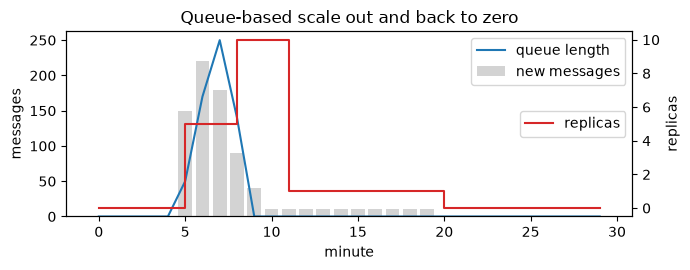

replica-minutes used: 54 | max queue: 250


In [11]:
def simulate_autoscale(arrivals, per_replica_rate=20, target_per_replica=30, min_r=0, max_r=10, cooldown=3):
    queue, replicas, last_change = 0, min_r, -99
    hist = []
    for t, new in enumerate(arrivals):
        queue += new
        desired = min(max_r, max(min_r, math.ceil(queue / target_per_replica)))
        if desired != replicas and t - last_change >= cooldown:   # KEDA-like: respect cooldown
            replicas, last_change = desired, t
        processed = min(queue, replicas * per_replica_rate)
        queue -= processed
        hist.append((t, new, queue, replicas))
    return pd.DataFrame(hist, columns=["minute", "arrivals", "queue", "replicas"])

arrivals = [0]*5 + [150, 220, 180, 90, 40] + [10]*10 + [0]*10        # an illustrative burst of uploads
df = simulate_autoscale(arrivals)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(df.minute, df.arrivals, color="lightgray", label="new messages")
ax.plot(df.minute, df.queue, label="queue length")
ax2 = ax.twinx(); ax2.step(df.minute, df.replicas, where="post", color="tab:red", label="replicas")
ax.set_xlabel("minute"); ax.set_ylabel("messages"); ax2.set_ylabel("replicas")
ax.legend(loc="upper right"); ax2.legend(loc="center right"); ax.set_title("Queue-based scale out and back to zero")
plt.tight_layout(); plt.show()
print("replica-minutes used:", int(df.replicas.sum()), "| max queue:", int(df.queue.max()))

Try changing `cooldown` or `min_r=1`: with `min_r=0` the worker costs nothing while idle but the first message waits for a **cold start**.

### 8.4 App Service, Azure Functions, Container Apps, Container Instances, AKS

- **App Service.** Host web apps and APIs from code (Python, Node, .NET, Java) or a container on an **App Service plan** (the VMs you pay for). Features: deployment slots (staging -> production swap), VNet integration, easy auth, managed certificates. Good for a FastAPI front end; see [Deployment concepts](../16_Deployment/01_deployment_concepts.ipynb).
- **Azure Functions.** Small functions run by **triggers** (HTTP, timer, blob, queue, Event Grid, Service Bus) with **bindings** for input and output. The **Flex Consumption** plan is now the recommended serverless plan (Linux, fast scaling, VNet support, always-ready instances option); the older Linux Consumption plan retires on 30 September 2028. **Durable Functions** add stateful workflows (fan-out/fan-in, human approval, long-running orchestration) and fit multi-step document pipelines. Functions can also host remote **MCP servers** for agents. See [Serverless deployment](../16_Deployment/03_serverless_deployment.ipynb).
- **Azure Container Apps (ACA).** Serverless containers on a managed Kubernetes base you never see: revisions with traffic splitting, Dapr, KEDA scaling, jobs (scheduled or event-driven), **serverless GPUs** (NVIDIA A100 / T4 in selected regions, per-second billing) for small model serving, and **dynamic sessions**: secure sandboxes for running LLM-generated code (Python code interpreter) or custom containers, one per user session.
- **Azure Container Instances (ACI).** Run a single container group in seconds without a cluster; good for short jobs and tests.
- **AKS.** Managed Kubernetes. The control plane is managed for you; you choose node pools (CPU, GPU, Spot). **AKS Automatic** picks secure defaults and manages nodes for you (node autoprovisioning). GPU workloads use the NVIDIA device plugin or GPU Operator; Microsoft's **AI toolchain operator (KAITO)** add-on can deploy open models such as vLLM-served LLMs on GPU node pools. AKS **Workload Identity** gives pods managed-identity style access. See [Kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb) and [Helm and GitOps](../17_Docker/03_helm_and_gitops.ipynb).

**When not to use AKS.** If you have one or two services and no platform team, Container Apps gives you most benefits with far less to operate.

## 9. Azure Container Registry (ACR)

**What it is.** A private registry for container images and other OCI artifacts (Helm charts, model files packaged as OCI).

**How it works and key features.**
- SKUs: **Basic, Standard, Premium**. Premium adds **geo-replication** (one registry, replicas in several regions), private endpoints and higher throughput.
- **ACR Tasks** build images in Azure (`az acr build`) with no local Docker, and can rebuild automatically when a base image changes.
- Pull with a managed identity that has the **AcrPull** role. Avoid the admin user account.
- Microsoft Defender for Cloud can scan images for vulnerabilities.

```bash
az acr create -g rg-chat-prod -n acrchatprod --sku Premium
az acr build -r acrchatprod -t chat-api:1.4.0 .        # builds in the cloud from your Dockerfile
az containerapp up -n chat-api -g rg-chat-prod --image acrchatprod.azurecr.io/chat-api:1.4.0
```

## 10. Storage and data services

### 10.1 Storage accounts, Blob tiers, Data Lake, Files and disks

**What it is.** A **storage account** (use general-purpose v2) is a namespace that holds **Blob** containers (objects), **Azure Files** shares (SMB/NFS file shares), **Queues** and **Tables**. Turning on the **hierarchical namespace** makes it **Azure Data Lake Storage (ADLS) Gen2**, with real folders and POSIX-like ACLs for analytics and Spark.

**Redundancy options.** LRS (3 copies in one datacenter), ZRS (across 3 zones), GRS / RA-GRS (plus a copy in the paired region, optionally readable), GZRS / RA-GZRS (zones plus a paired region).

**Blob access tiers.**

| Tier | Online? | Minimum storage period (early-deletion charge) | Use |
|---|---|---|---|
| Hot | yes | none | active datasets, RAG source documents |
| Cool | yes | 30 days | older logs, last month's checkpoints |
| Cold | yes | 90 days | rarely read data you still need quickly |
| Archive | **no** (rehydrate takes hours) | 180 days | compliance copies, old raw data |

**Lifecycle management** rules move or delete blobs by age ("move to cool after 30 days without modification"). **Smart tier** (generally available since 2026) automatically moves objects among hot, cool and cold based on access, without transition or retrieval charges for smart-tier objects; it does not use archive.

The toy compares keeping 12 monthly 500 GB training snapshots all in hot versus a lifecycle rule. **All prices are made-up relative units**, chosen only to show the shape of the trade-off.

In [12]:
PRICE = {"hot": 1.00, "cool": 0.55, "cold": 0.25, "archive": 0.06}   # made-up price units per GB-month
def tier_for(age_days, rule):
    if rule == "all-hot": return "hot"
    return "hot" if age_days < 30 else "cool" if age_days < 90 else "cold" if age_days < 180 else "archive"

rows = []
for rule in ["all-hot", "lifecycle"]:
    total = 0.0
    for month in range(24):                        # look at a 2-year window
        for snap in range(12):                     # 12 snapshots, one created each month
            if snap <= month:
                age = (month - snap) * 30
                total += 500 * PRICE[tier_for(age, rule)]
    rows.append({"policy": rule, "2-year storage cost (units)": round(total)})
print(pd.DataFrame(rows).to_string(index=False))
print("Reminder: reading from cool/cold/archive costs extra, and archive needs rehydration first.")

   policy  2-year storage cost (units)
  all-hot                       111000
lifecycle                        21600
Reminder: reading from cool/cold/archive costs extra, and archive needs rehydration first.


**Azure Files** gives SMB/NFS shares (for example a shared model cache for several containers, or lift-and-shift apps). **Managed disks** are block devices for VMs: Standard HDD, Standard SSD, Premium SSD, **Premium SSD v2** (tune IOPS and throughput independently) and **Ultra Disk** (highest performance). GPU VMs usually also have fast local NVMe temp disks: great for caching model weights, but **wiped** when the VM is deallocated.

### 10.2 Azure Cosmos DB

**What it is.** A globally distributed, multi-model NoSQL database with single-digit millisecond reads, automatic indexing, and multi-region writes. Popular for chat history, agent memory, user profiles and, with built-in **vector search** (DiskANN-based indexes) and full-text / hybrid search, for RAG.

**APIs.**

| API | Use when |
|---|---|
| **NoSQL** (recommended for new apps) | JSON documents with SQL-like queries, vector + hybrid search, change feed |
| MongoDB (RU-based) | existing MongoDB apps that want Cosmos DB's scaling model |
| Cassandra, Gremlin (graph), Table | compatibility with those ecosystems |
| **Azure DocumentDB** (formerly Cosmos DB for MongoDB vCore) | a separate MongoDB-compatible service built on the open-source DocumentDB engine; pick it for deep MongoDB compatibility |

**Key ideas.**
- **Request Units (RU/s)**: the currency of throughput. Roughly, a point read of a 1 KB item costs 1 RU; writes and queries cost more. Choose provisioned throughput (optionally autoscale) or serverless.
- **Partition key**: every item has a partition key value; items with the same value form a **logical partition** (limit 20 GB). Cosmos DB spreads logical partitions over physical partitions. A good key has **high cardinality**, spreads **writes evenly**, and appears in your **most common queries** (so they hit one partition). **Hierarchical partition keys** (up to three levels, for example `/tenantId/userId/sessionId`) help multi-tenant apps.
- **Consistency levels** (strongest to weakest): Strong, Bounded Staleness, **Session** (the default: you read your own writes), Consistent Prefix, Eventual.
- **Change feed**: an ordered log of changes, used to trigger embedding updates or sync to a search index.

The toy below scores candidate partition keys for a chat-history container.

In [13]:
rng = np.random.default_rng(SEED)
n = 20_000
tenants = rng.choice(["contoso", "fabrikam", "tailspin", "woodgrove"], size=n, p=[0.70, 0.15, 0.10, 0.05])  # one big tenant
users = [f"{t}-u{rng.integers(0, 400)}" for t in tenants]
sessions = [f"{u}-s{rng.integers(0, 30)}" for u in users]
msgs = pd.DataFrame({"tenantId": tenants, "userId": users, "sessionId": sessions,
                     "date": rng.choice(pd.date_range("2026-11-01", periods=7).strftime("%Y-%m-%d"), size=n)})

def score_key(col, typical_query_filter):
    counts = msgs[col].value_counts()
    return {"partition key": "/" + col, "distinct values": len(counts),
            "largest partition share": f"{counts.iloc[0] / n:.1%}",
            "top query hits one partition?": typical_query_filter == col}

# Typical query: "load the history of one chat session" -> filters on sessionId
report = pd.DataFrame([score_key(c, "sessionId") for c in ["tenantId", "date", "userId", "sessionId"]])
print(report.to_string(index=False))

partition key  distinct values largest partition share  top query hits one partition?
    /tenantId                4                   70.0%                          False
        /date                7                   14.7%                          False
      /userId             1570                    0.3%                          False
   /sessionId            13632                    0.0%                           True


`/tenantId` has a **hot partition** (70% of traffic) and `/date` sends all of today's writes to one partition. `/sessionId` spreads load and matches the main query. If you also often query "all sessions of a user", a hierarchical key `/userId/sessionId` keeps both queries efficient. For a deeper NoSQL background see [NoSQL databases](../13_Databases/02_nosql/01_nosql_databases.ipynb).

### 10.3 Azure SQL and Azure Database for PostgreSQL (Flexible Server)

- **Azure SQL Database / Managed Instance**: managed SQL Server engine; serverless tier with auto-pause; recent versions add a native vector type and vector functions (check the docs for your tier).
- **Azure Database for PostgreSQL Flexible Server**: managed PostgreSQL with zone-redundant high availability, VNet integration (delegated subnet) or private endpoints, and Entra ID authentication. For AI it supports the **pgvector** extension and Microsoft's **pg_diskann** extension (a DiskANN approximate nearest neighbour index that works with pgvector's types). Extensions must first be allow-listed in the server parameter `azure.extensions`.

```sql
-- after allow-listing VECTOR and PG_DISKANN in azure.extensions
CREATE EXTENSION IF NOT EXISTS vector;
CREATE EXTENSION IF NOT EXISTS pg_diskann CASCADE;
CREATE TABLE chunks (id bigserial PRIMARY KEY, doc_id text, body text, embedding vector(1536));
CREATE INDEX ON chunks USING diskann (embedding vector_cosine_ops);   -- or: USING hnsw (embedding vector_cosine_ops)
SELECT id, body FROM chunks WHERE doc_id = 'policy-42'
ORDER BY embedding <=> $1 LIMIT 5;                                     -- <=> is cosine distance
```
How vector indexes work inside is covered in [Advanced retrieval and reranking](../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb).

### 10.4 Azure Managed Redis (and the retiring Azure Cache for Redis)

**What it is.** A managed in-memory data store (based on Redis Enterprise software) for caching, session state, rate-limit counters, and **vector search** (RediSearch), which also powers **semantic caching** for LLM calls (section 11.5).

**Status as of late 2026.** Azure Cache for Redis is being retired: the Enterprise and Enterprise Flash tiers on 31 March 2027, and the Basic, Standard and Premium tiers on 30 September 2028 (new creation is already blocked). New work should use **Azure Managed Redis**. Caching strategies for LLMs are covered in [LLM caching](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb).

### 10.5 Analytics in one paragraph

**Microsoft Fabric** is the unified SaaS analytics platform (OneLake storage, Data Factory pipelines, Spark, warehouses, Power BI, real-time intelligence); **Azure Data Factory** remains the PaaS data integration service; **Azure Databricks** is the first-party Databricks offering; Synapse Analytics is the older integrated analytics service, with Fabric as the recommended direction. See [Spark locally](../13_Databases/06_data_engineering/03_spark_locally.ipynb) for the engine concepts.

## 11. Integration: messages, events, workflows and API Management

### 11.1 Message or event?

**What it is.** A **message** is a command or piece of work someone *must* handle ("embed document 42"). An **event** is a notification that something *happened* ("blob 42 was uploaded"); the sender does not care who reacts.

| Service | Model | Strengths | Typical AI use |
|---|---|---|---|
| **Service Bus** | queues and topics (messages) | ordered **sessions**, transactions, duplicate detection, **dead-letter queue**, peek-lock | reliable job queue for ingestion, long-running agent tasks |
| **Event Grid** | push-based events (CloudEvents schema), also MQTT | filters, fan-out to many handlers, retries | react to "blob created" -> start an embedding Function |
| **Event Hubs** | high-throughput event **stream** with partitions and consumer groups; Kafka-compatible endpoint; Capture to storage | millions of events per second, replay | clickstream or telemetry for online features, token-usage streams |
| **Storage Queues** | simple queues | cheap, simple | small background jobs |

**Simple analogy.** Service Bus is registered post with signature on delivery; Event Grid is a doorbell; Event Hubs is a conveyor belt that you can rewind.

### 11.2 Service Bus peek-lock and the dead-letter queue

**How it works.** In **peek-lock** mode a receiver gets a message and a **lock** for a short time. If it finishes, it calls *complete* and the message is deleted. If it crashes or *abandons*, the lock expires and the message becomes visible again with a higher **delivery count**. After `MaxDeliveryCount` attempts (default 10) the message moves to the **dead-letter queue (DLQ)**, where a human or a repair job can inspect it. This is how "poison" documents stop blocking the pipeline.

In [14]:
class ToyServiceBusQueue:
    def __init__(self, max_delivery_count=3):
        self.q, self.dlq, self.max_dc = deque(), [], max_delivery_count
    def send(self, body):
        self.q.append({"body": body, "delivery_count": 0})
    def receive_peek_lock(self):
        if not self.q: return None
        msg = self.q.popleft(); msg["delivery_count"] += 1
        return msg
    def complete(self, msg):
        pass                                     # deleted for good
    def abandon(self, msg):
        if msg["delivery_count"] >= self.max_dc:
            msg["reason"] = "MaxDeliveryCountExceeded"; self.dlq.append(msg)
        else:
            self.q.append(msg)                   # visible again for another try

def embed_document(body):
    if body.endswith(".corrupt.pdf"):
        raise ValueError("cannot parse PDF")
    if body.endswith(".flaky.pdf") and random.random() < 0.5:
        raise TimeoutError("embedding endpoint timed out")
    return f"embedded {body}"

bus = ToyServiceBusQueue(max_delivery_count=3)
for doc in ["a.pdf", "b.flaky.pdf", "c.corrupt.pdf", "d.pdf"]:
    bus.send(doc)
random.seed(1)
while (m := bus.receive_peek_lock()) is not None:
    try:
        print(f"try {m['delivery_count']}: {embed_document(m['body'])}"); bus.complete(m)
    except Exception as e:
        print(f"try {m['delivery_count']}: {m['body']} failed ({e}) -> abandon"); bus.abandon(m)
print("dead-letter queue:", bus.dlq)
random.seed(SEED)

try 1: embedded a.pdf
try 1: b.flaky.pdf failed (embedding endpoint timed out) -> abandon
try 1: c.corrupt.pdf failed (cannot parse PDF) -> abandon
try 1: embedded d.pdf
try 2: embedded b.flaky.pdf
try 2: c.corrupt.pdf failed (cannot parse PDF) -> abandon
try 3: c.corrupt.pdf failed (cannot parse PDF) -> abandon
dead-letter queue: [{'body': 'c.corrupt.pdf', 'delivery_count': 3, 'reason': 'MaxDeliveryCountExceeded'}]


### 11.3 Logic Apps

**What it is.** A low-code workflow service with hundreds of **connectors** (Office 365, SharePoint, SAP, Salesforce, SQL...). **Consumption** plans are serverless and per action; **Standard** plans run on dedicated compute, support VNet integration and local development. Newer Logic Apps features let workflows call AI models and act as tools for agents (check current docs for status). Logic Apps is the Azure-native cousin of the no-code tools in [No-code AI automation](../10_Agents/14_no_code_ai_automation_n8n_make_zapier.ipynb).

### 11.4 API Management (APIM)

**What it is.** A managed **API gateway** plus a **developer portal**. You publish APIs as **products**, give consumers **subscription keys** or OAuth, and attach **policies** (XML snippets that run on every request: rate limits, header changes, JWT validation, caching, retries).

**Simple analogy.** A hotel reception desk in front of all your services: it checks who you are, how many requests you may make, and which room (backend) to send you to.

### 11.5 The APIM AI gateway

**What it is.** A set of APIM capabilities for AI backends: language model APIs (OpenAI Chat Completions and Responses formats, Anthropic Messages in the v2 tiers, Google Vertex AI), self-hosted models, remote **MCP servers** and **A2A** agent APIs. It is part of APIM, not a separate product, and can also be attached to a Foundry resource ("AI gateway in Microsoft Foundry", preview) to set token quotas per project.

| Capability | Policy / feature | Why it matters |
|---|---|---|
| Token rate limits and quotas per consumer | `llm-token-limit` (tokens per minute or per period, by subscription key, IP or any expression) | one noisy app cannot use the whole TPM quota |
| Token metrics | `llm-emit-token-metric` with custom dimensions | charge-back and dashboards per team |
| Semantic caching | `llm-semantic-cache-lookup` / `llm-semantic-cache-store` with Azure Managed Redis | reuse answers for near-duplicate prompts |
| Content safety | `llm-content-safety` (calls Azure AI Content Safety) | moderate prompts before they reach a model |
| Load balancing | backend pools: round-robin, weighted, **priority**, session-aware | spend reserved **PTU** capacity first, overflow to pay-as-you-go |
| Circuit breaker | backend rules that honour `Retry-After` | stop sending to a throttled backend until it recovers |
| Keyless backends | managed identity to Foundry / Azure OpenAI | no API keys in the gateway |
| MCP | expose a REST API as an MCP server, or govern an existing one | one governed front door for agent tools |

The simulation below combines three of these: a per-app TPM limit, priority routing (PTU first, then pay-as-you-go), and a circuit breaker that trips when a backend answers `429` with `Retry-After`.

In [15]:
@dataclass
class Backend:
    name: str; priority: int; tpm: int
    used: int = 0; open_until: int = -1          # circuit-breaker state
    def try_serve(self, tokens, second):
        if second < self.open_until:
            return "open"
        if self.used + tokens > self.tpm:
            self.open_until = second + 10        # backend said 429, Retry-After: 10
            return 429
        self.used += tokens; return 200

class ToyAIGateway:
    def __init__(self, backends, per_app_tpm):
        self.backends = sorted(backends, key=lambda b: b.priority)
        self.per_app_tpm, self.app_used = per_app_tpm, Counter()
        self.log = Counter()
    def handle(self, app, tokens, second):
        if self.app_used[app] + tokens > self.per_app_tpm[app]:          # llm-token-limit
            self.log[(app, "429 from gateway (app quota)")] += 1; return
        for b in self.backends:                                           # priority load balancing
            r = b.try_serve(tokens, second)
            if r == 200:
                self.app_used[app] += tokens; self.log[(app, f"served by {b.name}")] += 1; return
        self.log[(app, "503 all backends busy")] += 1

gw = ToyAIGateway([Backend("ptu-swedencentral", 1, tpm=60_000), Backend("paygo-global", 2, tpm=200_000)],
                  per_app_tpm={"chat-web": 150_000, "batch-summariser": 40_000})
rng = np.random.default_rng(7)
for second in range(60):                        # one minute of traffic
    for _ in range(rng.poisson(4)):
        gw.handle("chat-web", int(rng.integers(300, 900)), second)
    if second % 3 == 0:
        gw.handle("batch-summariser", 4000, second)
out = pd.Series(gw.log).rename("requests").reset_index()
out.columns = ["app", "outcome", "requests"]
print(out.sort_values(["app", "outcome"]).to_string(index=False))

             app                      outcome  requests
batch-summariser 429 from gateway (app quota)        10
batch-summariser       served by paygo-global         5
batch-summariser  served by ptu-swedencentral         5
        chat-web 429 from gateway (app quota)         9
        chat-web       served by paygo-global       187
        chat-web  served by ptu-swedencentral        67


**Real policy (fragment):**
```xml
<inbound>
  <authentication-managed-identity resource="https://cognitiveservices.azure.com" />
  <llm-token-limit counter-key="@(context.Subscription.Id)" tokens-per-minute="150000"
                   estimate-prompt-tokens="true" remaining-tokens-header-name="x-remaining-tokens" />
  <llm-emit-token-metric namespace="llm-metrics">
    <dimension name="App" value="@(context.Subscription.Name)" />
  </llm-emit-token-metric>
  <set-backend-service backend-id="foundry-pool" />   <!-- pool: PTU priority 1, pay-as-you-go priority 2 -->
</inbound>
```
PTU and pay-as-you-go deployment types are explained in notebook 09; how rate limits feel from the client side is in [Tokens, cost, batch and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb).

## 12. Observability: Azure Monitor, Log Analytics, KQL and Application Insights

**What it is.** **Azure Monitor** is the umbrella for metrics, logs, alerts and dashboards. **Log Analytics workspaces** store logs in tables that you query with **KQL** (Kusto Query Language). **Application Insights** is the application performance monitoring part: requests, dependencies (calls to databases or models), exceptions, traces and custom metrics, now collected mainly with the **Azure Monitor OpenTelemetry Distro**. Azure Monitor also offers managed Prometheus and Azure Managed Grafana for Kubernetes metrics.

**Simple analogy.** Metrics are the car's dashboard needles (numbers over time); logs are the trip diary (detailed records); traces are the GPS track of one journey across many roads (services).

**How it works.**
- Platform **metrics** arrive automatically. **Resource logs** need a **diagnostic setting** that sends them to a workspace (often enforced by policy).
- Alert rules (metric or log query) trigger **action groups** (email, Teams, webhook, Logic App, Function).
- Workspace-based Application Insights writes to tables such as `AppRequests`, `AppDependencies`, `AppTraces`, `AppExceptions`.

**KQL basics.** A query starts with a table and pipes rows through operators: `where` (filter), `project` (choose columns), `extend` (add a column), `summarize ... by ...` (group and aggregate), `bin()` (time buckets), `order by`, `take`, `join`, `render`.

```kusto
AppDependencies
| where TimeGenerated > ago(1h) and Type == "HTTP" and Target has "openai.azure.com"
| summarize calls = count(), p95_ms = percentile(DurationMs, 95), errors = countif(Success == false)
    by bin(TimeGenerated, 5m), Name
| order by TimeGenerated asc
```

The toy below implements a small subset of KQL (`where` with `and`, `project`, `extend` with simple arithmetic, `summarize` with `count()`, `sum()`, `avg()`, `max()`, `percentile(col, p)` and `bin(col, Nm)`, `order by`, `take`) on a pandas DataFrame, so you can practise the syntax offline.

In [16]:
# Toy "AppRequests" table for an AI chat API (synthetic data)
rng = np.random.default_rng(SEED)
N = 600
AppRequests = pd.DataFrame({
    "TimeGenerated": pd.Timestamp("2026-11-13 09:00") + pd.to_timedelta(np.sort(rng.integers(0, 3600, N)), unit="s"),
    "Name": rng.choice(["POST /chat", "POST /search", "GET /health"], size=N, p=[0.6, 0.3, 0.1]),
    "Deployment": rng.choice(["gpt-chat", "gpt-mini"], size=N, p=[0.7, 0.3]),
    "DurationMs": np.round(rng.lognormal(6.3, 0.6, N)),
    "ResultCode": rng.choice([200, 200, 200, 200, 429, 500], size=N),
    "TotalTokens": rng.integers(200, 3000, N),
})
TABLES = {"AppRequests": AppRequests}

def _value(tok):
    tok = tok.strip()
    if tok.startswith(("'", '"')): return tok[1:-1]
    try: return float(tok) if "." in tok else int(tok)
    except ValueError: return tok

def _where(df, expr):
    mask = pd.Series(True, index=df.index)
    for part in re.split(r"\s+and\s+", expr):
        m = re.fullmatch(r"\s*(\w+)\s*(==|!=|>=|<=|>|<|contains|has)\s*(.+?)\s*", part)
        col, op, val = m.group(1), m.group(2), _value(m.group(3))
        s = df[col]
        mask &= {"==": s == val, "!=": s != val, ">": s > val, "<": s < val, ">=": s >= val, "<=": s <= val,
                 "contains": s.astype(str).str.contains(str(val), case=False),
                 "has": s.astype(str).str.contains(rf"\b{re.escape(str(val))}\b", case=False)}[op]
    return df[mask]

def _summarize(df, expr):
    aggs, _, by = expr.partition(" by ")
    keys = []
    for b in [x.strip() for x in re.split(r",\s*(?![^()]*\))", by) if x.strip()]:
        m = re.fullmatch(r"bin\((\w+),\s*(\d+)m\)", b)
        if m:
            df = df.assign(**{m.group(1): df[m.group(1)].dt.floor(f"{m.group(2)}min")}); keys.append(m.group(1))
        else:
            keys.append(b)
    out = {}
    for a in re.split(r",\s*(?![^()]*\))", aggs):
        name, _, fn = a.partition("=")
        name, fn = (name.strip(), fn.strip()) if fn else (None, name.strip())
        m = re.fullmatch(r"(\w+)\(([^)]*)\)", fn)
        f, args = m.group(1), [x.strip() for x in m.group(2).split(",") if x.strip()]
        g = df.groupby(keys) if keys else df.assign(_all=0).groupby("_all")
        if f == "count":        res = g.size()
        elif f == "percentile": res = g[args[0]].quantile(float(args[1]) / 100)
        else:                   res = getattr(g[args[0]], {"avg": "mean"}.get(f, f))()
        out[name or f"{f}_{args[0] if args else ''}".rstrip("_")] = res
    return pd.DataFrame(out).reset_index().drop(columns="_all", errors="ignore")

def kql(query):
    stages = [s.strip() for s in query.strip().split("|")]
    df = TABLES[stages[0]].copy()
    for st in stages[1:]:
        op, _, rest = st.partition(" ")
        if op == "where":       df = _where(df, rest)
        elif op == "project":   df = df[[c.strip() for c in rest.split(",")]]
        elif op == "extend":
            name, expr = [x.strip() for x in rest.split("=", 1)]
            df = df.assign(**{name: df.eval(expr)})
        elif op == "summarize": df = _summarize(df, rest)
        elif op == "order":
            col, *direction = rest.replace("by ", "", 1).split()
            df = df.sort_values(col, ascending=(direction[:1] == ["asc"]))
        elif op == "take":      df = df.head(int(rest))
        else: raise ValueError(f"operator not supported in this toy: {op}")
    return df.reset_index(drop=True)

q1 = """AppRequests
| where Name == 'POST /chat' and ResultCode != 200
| summarize failures = count() by ResultCode, Deployment
| order by failures desc"""
print(q1); print(kql(q1).to_string(index=False), "\n")

q2 = """AppRequests
| where Name != 'GET /health'
| extend CostUnits = TotalTokens / 1000
| summarize calls = count(), p95_ms = percentile(DurationMs, 95), tokens = sum(TotalTokens) by bin(TimeGenerated, 15m)
| order by TimeGenerated asc"""
print(q2); print(kql(q2).to_string(index=False))

AppRequests
| where Name == 'POST /chat' and ResultCode != 200
| summarize failures = count() by ResultCode, Deployment
| order by failures desc
 ResultCode Deployment  failures
        429   gpt-chat        42
        500   gpt-chat        39
        429   gpt-mini        17
        500   gpt-mini        15 

AppRequests
| where Name != 'GET /health'
| extend CostUnits = TotalTokens / 1000
| summarize calls = count(), p95_ms = percentile(DurationMs, 95), tokens = sum(TotalTokens) by bin(TimeGenerated, 15m)
| order by TimeGenerated asc
      TimeGenerated  calls  p95_ms  tokens
2026-11-13 09:00:00    136  1212.0  225771
2026-11-13 09:15:00    138  1350.7  232278
2026-11-13 09:30:00    125  1243.4  201983
2026-11-13 09:45:00    143  1380.3  237829


**What just happened?** The first query finds which model deployment returns throttling (`429`) or server errors. The second builds a 15-minute latency and token report, the kind of chart you pin to a dashboard and alert on (for example "p95 latency above 4 s for 10 minutes"). Observability concepts beyond Azure are in [Observability hands-on](../15_MLOps/16_observability_hands_on.ipynb); tracing of agents and LLM calls in Foundry is in notebook 09.

**Real setup (not run here):**
```python
# pip install azure-monitor-opentelemetry
from azure.monitor.opentelemetry import configure_azure_monitor
configure_azure_monitor(connection_string="InstrumentationKey=...;IngestionEndpoint=...")
# From here, FastAPI requests, HTTP calls and logging are exported to Application Insights.
```

## 13. Infrastructure as code: ARM, Bicep, Terraform, azd and Azure CLI

**What it is.** Describing your Azure resources in files kept in Git, so environments are repeatable, reviewable and easy to recreate. See also [GitHub Actions CI/CD](../20_Git_and_DevOps/03_github_actions_cicd.ipynb).

| Tool | What it is | Notes |
|---|---|---|
| **ARM templates** | JSON documents sent to Azure Resource Manager | the native format; verbose; everything else compiles to or calls it |
| **Bicep** | a cleaner language that compiles to ARM JSON | day-zero support for new resource types, modules, `what-if`, **deployment stacks**, Azure Verified Modules |
| **Terraform** (`azurerm` provider, plus `azapi` for brand-new APIs) | HashiCorp's multi-cloud IaC with a state file | good when you also manage AWS/GCP/GitHub; state must be stored safely (for example a storage account with locking) |
| **Azure Developer CLI (`azd`)** | a developer workflow tool: `azd init`, `azd up`, `azd deploy`, `azd down` | uses Bicep or Terraform plus an `azure.yaml` app description; many AI templates (including Foundry agent templates) ship as azd projects |
| **Azure CLI (`az`)** | imperative commands | scripts, quick checks, CI steps; `az deployment group create` runs Bicep/ARM |

**Bicep example (not run):**
```bicep
param location string = resourceGroup().location
resource st 'Microsoft.Storage/storageAccounts@2023-05-01' = {
  name: 'stchatdocs${uniqueString(resourceGroup().id)}'
  location: location
  sku: { name: 'Standard_ZRS' }
  kind: 'StorageV2'
  properties: { allowSharedKeyAccess: false, publicNetworkAccess: 'Disabled', minimumTlsVersion: 'TLS1_2' }
}
output blobEndpoint string = st.properties.primaryEndpoints.blob
```
```bash
az deployment group what-if  -g rg-chat-dev -f main.bicep     # preview changes
az deployment group create   -g rg-chat-dev -f main.bicep
az stack group create -n chat-stack -g rg-chat-prod -f main.bicep \
   --action-on-unmanage deleteResources --deny-settings-mode denyDelete   # deployment stack
```

**Terraform example (not run):**
```hcl
resource "azurerm_storage_account" "docs" {
  name                          = "stchatdocs001"
  resource_group_name           = azurerm_resource_group.rg.name
  location                      = "swedencentral"
  account_tier                  = "Standard"
  account_replication_type      = "ZRS"
  shared_access_key_enabled     = false
  public_network_access_enabled = false
}
```

**Deployment modes.** ARM/Bicep group deployments default to **incremental** (add or update what is in the file, leave other resources alone). **Complete** mode deletes resources in the group that are not in the file; deployment stacks are the safer modern way to get "remove what I no longer declare". The toy below imitates `what-if`: compare desired state with current state and list Create / Modify / Delete / NoChange.

In [17]:
current = {
    "stchatdocs": {"type": "storageAccounts", "sku": "Standard_LRS", "publicNetworkAccess": "Enabled"},
    "kv-chat": {"type": "vaults", "enablePurgeProtection": True},
    "old-vm": {"type": "virtualMachines", "size": "Standard_D4s_v5"},
}
desired = {
    "stchatdocs": {"type": "storageAccounts", "sku": "Standard_ZRS", "publicNetworkAccess": "Disabled"},
    "kv-chat": {"type": "vaults", "enablePurgeProtection": True},
    "aca-chat-api": {"type": "containerApps", "minReplicas": 1},
}

def what_if(current, desired, mode="incremental"):
    rows = []
    for name in sorted(set(current) | set(desired)):
        cur, want = current.get(name), desired.get(name)
        if cur is None:
            rows.append((name, "Create", ""))
        elif want is None:
            rows.append((name, "Delete" if mode == "complete" else "Ignore (not in template)", ""))
        else:
            diffs = [f"{k}: {cur.get(k)} -> {v}" for k, v in want.items() if cur.get(k) != v]
            rows.append((name, "Modify" if diffs else "NoChange", "; ".join(diffs)))
    return pd.DataFrame(rows, columns=["resource", "change", "details"])

print(what_if(current, desired).to_string(index=False))
print()
print(what_if(current, desired, mode="complete").to_string(index=False))

    resource                   change                                                                     details
aca-chat-api                   Create                                                                            
     kv-chat                 NoChange                                                                            
      old-vm Ignore (not in template)                                                                            
  stchatdocs                   Modify sku: Standard_LRS -> Standard_ZRS; publicNetworkAccess: Enabled -> Disabled

    resource   change                                                                     details
aca-chat-api   Create                                                                            
     kv-chat NoChange                                                                            
      old-vm   Delete                                                                            
  stchatdocs   Modify sku: Standard_L

## 14. Azure DevOps: Boards, Repos, Pipelines, Test Plans, Artifacts

**What it is.** Microsoft's suite for planning and shipping software, older than GitHub's Actions but still widely used in enterprises.

| Service | What it does | GitHub equivalent |
|---|---|---|
| **Azure Boards** | work items, backlogs, sprints, Kanban | GitHub Issues / Projects |
| **Azure Repos** | Git repositories, pull requests, branch policies | GitHub repositories |
| **Azure Pipelines** | CI/CD defined in YAML (`azure-pipelines.yml`), Microsoft-hosted or self-hosted agents | GitHub Actions |
| **Azure Test Plans** | manual and exploratory test management | (third-party tools) |
| **Azure Artifacts** | package feeds (PyPI, npm, NuGet, Maven) with upstream sources | GitHub Packages |

**Pipeline structure.** `trigger` -> `stages` -> `jobs` -> `steps` (scripts or **tasks** such as `AzureCLI@2`). **Environments** add approvals and checks before a stage deploys. **Service connections** hold the identity used to reach Azure; prefer **workload identity federation** (no secret) over client secrets. Templates let many repos share one pipeline definition.

```yaml
trigger:
  branches: { include: [ main ] }
pool:
  vmImage: ubuntu-latest
stages:
- stage: build
  jobs:
  - job: test_and_package
    steps:
    - script: pip install -r requirements.txt && pytest -q
    - script: az acr build -r acrchatprod -t chat-api:$(Build.BuildId) .
- stage: deploy_dev
  dependsOn: build
  jobs:
  - deployment: dev
    environment: chat-dev                      # approvals and checks live on the environment
    strategy:
      runOnce:
        deploy:
          steps:
          - task: AzureCLI@2
            inputs:
              azureSubscription: sc-chat-dev-wif   # service connection using workload identity federation
              scriptType: bash
              scriptLocation: inlineScript
              inlineScript: >
                az containerapp update -n chat-api -g rg-chat-dev
                --image acrchatprod.azurecr.io/chat-api:$(Build.BuildId)
- stage: eval_gate
  dependsOn: deploy_dev
  jobs:
  - job: run_ai_evals
    steps:
    - script: python evals/run.py --min-groundedness 4.0   # fail the stage if quality drops
- stage: deploy_prod
  dependsOn: eval_gate
  jobs:
  - deployment: prod
    environment: chat-prod
    strategy:
      runOnce:
        deploy:
          steps:
          - script: echo "same deploy step as dev, prod service connection"
```

The toy below reads the stage graph and prints the run order, waiting at environments that need approval. Note the **AI evaluation gate** before production: quality checks on a test set belong in CI/CD just like unit tests (see notebook 09, section 9).

In [18]:
pipeline = {
    "build":       {"dependsOn": [],                 "environment": None},
    "deploy_dev":  {"dependsOn": ["build"],          "environment": "chat-dev"},
    "eval_gate":   {"dependsOn": ["deploy_dev"],     "environment": None},
    "security_scan": {"dependsOn": ["build"],        "environment": None},
    "deploy_prod": {"dependsOn": ["eval_gate", "security_scan"], "environment": "chat-prod"},
}
approvals_needed = {"chat-prod"}                       # environment check configured in Azure DevOps

ts = TopologicalSorter({k: v["dependsOn"] for k, v in pipeline.items()})
ts.prepare(); wave = 1
while ts.is_active():
    ready = sorted(ts.get_ready())
    notes = [f"{s} (waits for approval on {pipeline[s]['environment']})" if pipeline[s]["environment"] in approvals_needed else s
             for s in ready]
    print(f"wave {wave}: run in parallel -> {notes}")
    ts.done(*ready); wave += 1

wave 1: run in parallel -> ['build']
wave 2: run in parallel -> ['deploy_dev', 'security_scan']
wave 3: run in parallel -> ['eval_gate']
wave 4: run in parallel -> ['deploy_prod (waits for approval on chat-prod)']


## 15. Security services: Key Vault, Defender for Cloud, Sentinel

### 15.1 Azure Key Vault

**What it is.** A managed safe for **secrets** (connection strings, third-party API keys), **keys** (encryption keys, optionally in HSMs) and **certificates**.

**How it works and good practice.**
- Use the **Azure RBAC permission model** (roles such as Key Vault Secrets User / Officer) rather than legacy access policies.
- Turn on **soft delete** (on by default) and **purge protection**, so deleted secrets can be recovered and cannot be destroyed immediately.
- Apps read secrets with their **managed identity**; App Service, Functions and Container Apps can reference Key Vault secrets directly in app settings.
- Rotate secrets on a schedule (Event Grid can notify when a secret is near expiry). Better still, avoid secrets altogether with managed identities.
- Disable public access and use a private endpoint.

Related: **Azure App Configuration** stores non-secret settings and feature flags and can point to Key Vault for secret values.

### 15.2 Microsoft Defender for Cloud

**What it is.** Cloud security posture management (CSPM) plus workload protection. It continuously checks your resources against recommendations (a **secure score**), finds attack paths, scans VMs and container images for vulnerabilities, and offers protection plans for servers, storage, databases, containers, Key Vault, APIs and **AI services** (threat protection for AI workloads, for example alerts on prompt-injection attempts or unusual model usage). Defender alerts also surface in the Foundry Control Plane (notebook 09).

### 15.3 Microsoft Sentinel

**What it is.** A cloud-native SIEM and SOAR: it collects security logs from Azure, Microsoft 365 and third parties into a Log Analytics workspace (and the Sentinel data lake), detects threats with analytics rules written in **KQL**, and automates responses with playbooks (Logic Apps). As of late 2026, Sentinel is moving fully into the **Microsoft Defender portal**; the Azure portal experience is scheduled to retire on 31 March 2027.

The toy below checks a few resources against an AI-app security baseline and computes a "posture score". This is **not** Defender's real secure-score formula, only the idea.

In [19]:
resources = [
    {"name": "aoai-chat", "kind": "foundry", "public": False, "local_auth": False, "private_endpoint": True, "diag": True},
    {"name": "stchatdocs", "kind": "storage", "public": True, "local_auth": True, "private_endpoint": False, "diag": True},
    {"name": "kv-chat", "kind": "keyvault", "public": False, "purge_protection": False, "rbac_mode": True, "diag": False},
    {"name": "aca-chat-api", "kind": "containerapp", "managed_identity": True, "secrets_in_env": True, "diag": True},
]
CHECKS = [  # (applies to kind, description, test, weight)
    ({"foundry", "storage", "keyvault"}, "public network access disabled", lambda r: not r.get("public", True), 3),
    ({"foundry", "storage"}, "key-based (local) auth disabled", lambda r: not r.get("local_auth", True), 3),
    ({"foundry", "storage"}, "private endpoint configured", lambda r: r.get("private_endpoint", False), 2),
    ({"keyvault"}, "purge protection on", lambda r: r.get("purge_protection", False), 2),
    ({"keyvault"}, "RBAC permission model", lambda r: r.get("rbac_mode", False), 1),
    ({"containerapp"}, "uses managed identity", lambda r: r.get("managed_identity", False), 2),
    ({"containerapp"}, "no plain secrets in env vars", lambda r: not r.get("secrets_in_env", True), 2),
    (None, "diagnostic settings to Log Analytics", lambda r: r.get("diag", False), 1),
]
got = total = 0; findings = []
for r in resources:
    for kinds, desc, test, w in CHECKS:
        if kinds is None or r["kind"] in kinds:
            total += w
            if test(r): got += w
            else: findings.append((r["name"], desc, w))
print(f"toy posture score: {got}/{total} = {got/total:.0%}")
print(pd.DataFrame(findings, columns=["resource", "failed check", "weight"]).sort_values("weight", ascending=False).to_string(index=False))

toy posture score: 17/30 = 57%
    resource                         failed check  weight
  stchatdocs       public network access disabled       3
  stchatdocs      key-based (local) auth disabled       3
  stchatdocs          private endpoint configured       2
     kv-chat                  purge protection on       2
aca-chat-api         no plain secrets in env vars       2
     kv-chat diagnostic settings to Log Analytics       1


## 16. Hybrid and edge: Azure Arc and Azure Local

**Azure Arc.** Projects resources that run **outside** Azure (on-premises servers, Kubernetes clusters in other clouds or factories, SQL Server, VMware) into Azure Resource Manager. Once connected they appear in resource groups, so you can apply the same **RBAC, Azure Policy, Defender, Monitor and tags** to them, and deploy extensions (for example GitOps with Flux on Arc-enabled Kubernetes).

**Azure Local (formerly Azure Stack HCI).** Microsoft-validated hardware in your own datacenter or branch, running Azure's hyperconverged stack and managed through Arc. Use it for data-residency, low-latency or disconnected sites. Microsoft Foundry can deploy eligible models to **Foundry Local on Azure Local** (preview), running on Arc-enabled Kubernetes clusters you own (notebook 09).

**Simple analogy.** Arc is a remote-control app that lets you manage your own appliances from the same Azure dashboard; Azure Local is a small Azure "branch office" you own.

**When to use.** Factories, hospitals, retail stores and regulated industries that must keep data or inference on-site, but want one management plane. For on-device apps (laptops, PCs) see **Foundry Local** in notebook 09 and [Edge deployment](../16_Deployment/04_edge_deployment.ipynb).

## 17. Reference architecture: a secure RAG chat app on Azure

Below is a common, private-by-default layout for a retrieval-augmented chat assistant. The AI pieces (Foundry project, model deployments, Foundry Agent Service, Azure AI Search / Foundry IQ, Content Safety) are explained in [notebook 09](09_azure_ai_microsoft_foundry_and_azure_openai.ipynb); everything else is from this notebook.

```mermaid
flowchart LR
    user[Users / browser] --> fd[Azure Front Door + WAF]
    fd -->|Private Link origin| aca[Container Apps: chat API<br/>managed identity]
    subgraph spoke[Spoke VNet: ai-chat-prod subscription]
        aca --> apim[API Management<br/>AI gateway: token limits, PTU-first routing]
        apim --> pe1((PE)) --> foundry[Microsoft Foundry resource<br/>model deployments + agents]
        aca --> pe2((PE)) --> search[Azure AI Search / Foundry IQ]
        aca --> pe3((PE)) --> cosmos[Cosmos DB for NoSQL<br/>chat history]
        aca --> pe4((PE)) --> kv[Key Vault]
        ingest[Functions Flex: ingest + chunk] --> pe5((PE)) --> blob[Blob Storage: source docs]
        blob -- Event Grid: BlobCreated --> sb[Service Bus queue] --> ingest
        ingest --> search
    end
    subgraph hub[Hub VNet: connectivity subscription]
        fw[Azure Firewall] --- dns[Private DNS zones]
    end
    spoke <-->|peering| hub
    aca -. OpenTelemetry .-> ai[Application Insights + Log Analytics]
    apim -. token metrics .-> ai
    foundry -. traces / evals .-> ai
    policy[Azure Policy + Defender for Cloud] -. govern .-> spoke
```

**Walkthrough.**
1. **Entry:** Front Door terminates TLS at the edge and applies WAF rules; it reaches the Container App over Private Link, so the app has no public ingress.
2. **Identity:** the Container App has a **user-assigned managed identity** with data-plane roles only: Foundry User (or Cognitive Services OpenAI User) on the Foundry resource via APIM, Search Index Data Reader on AI Search, a Cosmos DB data role, Key Vault Secrets User. No API keys anywhere (`disableLocalAuth` enforced by policy).
3. **Network:** every PaaS service has **public network access disabled** and a **private endpoint** in the spoke; DNS resolves through private DNS zones linked from the hub. Outbound internet from the spoke goes through Azure Firewall.
4. **Model traffic:** the app calls models through **APIM's AI gateway**, which enforces per-app token limits, sends traffic to PTU deployments first, spills over to pay-as-you-go, and emits token metrics.
5. **Ingestion:** uploads land in Blob Storage, Event Grid raises `BlobCreated`, a Service Bus queue buffers work, a Flex Consumption Function chunks and embeds documents and writes to the search index; poison documents go to the dead-letter queue.
6. **Observability and governance:** OpenTelemetry to Application Insights; KQL alerts on latency, 429s and error rates; Azure Policy and Defender for Cloud on the whole landing zone; everything deployed with Bicep or Terraform through a pipeline with an evaluation gate.

## 18. Azure Well-Architected Framework checklist

**What it is.** Microsoft's guidance for good cloud workloads, in five **pillars**: Reliability, Security, Cost Optimization, Operational Excellence, Performance Efficiency. There is also specific guidance for AI workloads on Azure.

| Pillar | Questions to ask for an AI app | Azure features from this notebook |
|---|---|---|
| **Reliability** | What happens if one zone, region or model deployment fails or throttles? | availability zones, ZRS/GZRS storage, multi-region Front Door, APIM backend pools + circuit breaker, retries with backoff, Service Bus DLQ |
| **Security** | Are there any keys, public endpoints or over-broad roles? | Entra ID, managed identities, least-privilege RBAC at low scopes, private endpoints, Key Vault, Policy, Defender, content safety |
| **Cost Optimization** | Do we pay for idle GPUs or wasted tokens? | scale to zero, Spot, reservations, Blob tiers / smart tier, semantic cache, batch deployments, budgets and tags |
| **Operational Excellence** | Can we redeploy everything from Git and see what is happening? | Bicep/Terraform, azd, pipelines with approvals and eval gates, App Insights, KQL alerts, runbooks |
| **Performance Efficiency** | Is latency acceptable at peak, and does it scale? | right-sized SKUs, autoscale rules, PTU for steady load, caching (Managed Redis), regional proximity to users and data |

The scorer below turns a checklist into per-pillar percentages, the way an architecture review might.

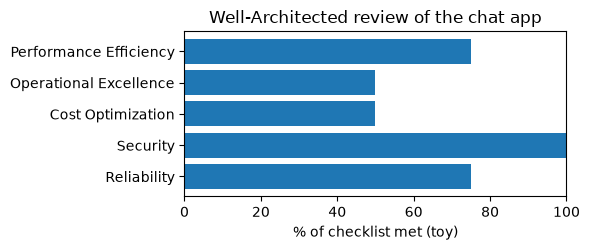

Reliability                75%  to do: ['multi-region or failover plan']
Security                  100%  to do: -
Cost Optimization          50%  to do: ['semantic cache / batch where possible', 'tags on all resources']
Operational Excellence     50%  to do: ['pipeline with eval gate', 'runbook for model deprecation']
Performance Efficiency     75%  to do: ['load test at 2x peak']


In [20]:
checklist = {
    "Reliability": {"zone-redundant storage and app": True, "multi-region or failover plan": False,
                     "retries + circuit breaker to models": True, "DLQ monitored": True},
    "Security": {"no API keys (disableLocalAuth)": True, "private endpoints for all PaaS": True,
                  "least-privilege RBAC via groups/MI": True, "prompt-injection and content filters": True},
    "Cost Optimization": {"budgets + alerts": True, "scale to zero for workers": True,
                           "semantic cache / batch where possible": False, "tags on all resources": False},
    "Operational Excellence": {"all infra in IaC": True, "pipeline with eval gate": False,
                                "dashboards + KQL alerts": True, "runbook for model deprecation": False},
    "Performance Efficiency": {"load test at 2x peak": False, "PTU sized for steady load": True,
                                "cache hot data in Redis": True, "app in same region as model + data": True},
}
scores = {p: 100 * sum(v.values()) / len(v) for p, v in checklist.items()}
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(list(scores), list(scores.values()), color="tab:blue"); ax.set_xlim(0, 100)
ax.set_xlabel("% of checklist met (toy)"); ax.set_title("Well-Architected review of the chat app"); plt.tight_layout(); plt.show()
for p, items in checklist.items():
    todo = [k for k, ok in items.items() if not ok]
    print(f"{p:23s} {scores[p]:5.0f}%  to do: {todo or '-'}")

## 19. Service map: Azure vs AWS vs GCP

Names are the closest equivalents, not exact matches. See also [AWS for AI](01_aws_for_ai.ipynb) and [GCP for AI](02_gcp_for_ai.ipynb).

| Need | Azure | AWS | Google Cloud |
|---|---|---|---|
| Org hierarchy | tenant, management groups, subscriptions, resource groups | Organizations, OUs, accounts | organization, folders, projects |
| Identity directory | Microsoft Entra ID | IAM Identity Center (+ IAM) | Cloud Identity / Google Workspace |
| Access control | Azure RBAC role assignments | IAM policies and roles | IAM roles and bindings |
| Identity for workloads | managed identities, workload identity federation | IAM roles for EC2/Lambda, EKS Pod Identity | service accounts, Workload Identity Federation |
| Org-wide guardrails | Azure Policy, management-group policy | SCPs, AWS Config rules, Control Tower | Organization Policy Service |
| Landing zone | CAF landing zones, Azure Verified Modules | Control Tower / Landing Zone Accelerator | Google Cloud setup / Fabric FAST |
| Private network | VNet, subnets, NSG | VPC, subnets, security groups / NACLs | VPC, subnets, firewall rules |
| Private access to PaaS | Private Link / private endpoints | PrivateLink / VPC endpoints | Private Service Connect |
| L7 load balancer / global edge | Application Gateway / Front Door | ALB / CloudFront + Global Accelerator | Cloud Load Balancing / Cloud CDN |
| VMs / scale sets | Virtual Machines, VM Scale Sets | EC2, Auto Scaling groups | Compute Engine, managed instance groups |
| GPU VMs | ND / NC series | P / G instances (and Trainium/Inferentia) | A3/A4 GPU VMs (and TPUs) |
| Serverless functions | Azure Functions (Flex Consumption) | Lambda | Cloud Run functions |
| Serverless containers | Container Apps | ECS Express Mode / Fargate | Cloud Run |
| Managed Kubernetes | AKS (AKS Automatic) | EKS (EKS Auto Mode) | GKE (Autopilot) |
| Container registry | Azure Container Registry | ECR | Artifact Registry |
| Object storage | Blob Storage / ADLS Gen2 | S3 | Cloud Storage |
| Global NoSQL | Cosmos DB | DynamoDB | Firestore / Bigtable |
| Managed PostgreSQL + vectors | PostgreSQL Flexible Server (pgvector, pg_diskann) | RDS / Aurora PostgreSQL (pgvector) | Cloud SQL / AlloyDB (pgvector) |
| Managed Redis | Azure Managed Redis | ElastiCache / MemoryDB | Memorystore |
| Message queue | Service Bus | SQS / Amazon MQ | Pub/Sub |
| Event routing | Event Grid | EventBridge | Eventarc |
| Event streaming | Event Hubs (Kafka API) | Kinesis / MSK | Pub/Sub / Managed Kafka |
| Low-code workflows | Logic Apps | Step Functions (+ AppFlow) | Workflows / Application Integration |
| API gateway + AI gateway | API Management (AI gateway) | API Gateway (+ Bedrock features) | Apigee |
| Monitoring + logs query | Azure Monitor, Log Analytics (KQL), App Insights | CloudWatch (Logs Insights), X-Ray | Cloud Monitoring, Cloud Logging, Cloud Trace |
| Native IaC | ARM / Bicep, deployment stacks | CloudFormation / CDK | Infrastructure Manager (Terraform) |
| Secrets | Key Vault | Secrets Manager / KMS | Secret Manager / Cloud KMS |
| Security posture / SIEM | Defender for Cloud / Sentinel | Security Hub, GuardDuty / (partners) | Security Command Center / Google SecOps |
| Hybrid management | Azure Arc, Azure Local | Systems Manager, EKS Anywhere, Outposts | Google Distributed Cloud |

## 20. How to try it for real (cheaply)

- **Free account and sandboxes.** An Azure free account gives limited credit and some always-free services; Microsoft Learn modules often include a temporary sandbox subscription. Set a **budget alert** on day one.
- **Azure CLI and Bicep locally.** Install `az`, run `az login`, then `az bicep build -f main.bicep` and `az deployment group what-if` to see changes without applying them.
- **Azure Developer CLI.** `azd init` with a template, `azd up` to provision and deploy, `azd down --purge` to delete everything afterwards.
- **Local emulators (no subscription needed):** **Azurite** (Blob, Queue, Table storage), the **Azure Cosmos DB emulator** (Windows or Linux container), the **Service Bus emulator** and **Event Hubs emulator** (containers), **Azure Functions Core Tools** (`func start`), and `docker` for container images. For Kubernetes practice use **kind** or minikube before AKS.
- **KQL practice.** Microsoft provides a free demo Log Analytics workspace and the Azure Data Explorer help cluster with sample data; the toy in section 12 works offline.
- **Terraform.** `terraform plan` against a throwaway resource group; store state in a storage account only once you share it.
- **Clean up.** Delete resource groups when done; GPU VMs, Front Door, Firewall and APIM premium tiers are the usual surprise bills.

## 21. Certification topic map

Exam names change; check the current study guides on Microsoft Learn. As of late 2026:

| Exam | Title (current) | Sections of this notebook |
|---|---|---|
| AZ-900 | Microsoft Azure Fundamentals | 1, 2, 3, 4, 7, 8, 10 (concepts) |
| AZ-104 | Microsoft Azure Administrator | 2-10, 12, 15 (identity, governance, networking, compute, storage, monitoring) |
| AZ-305 | Designing Microsoft Azure Infrastructure Solutions | 6, 7, 10, 11, 17, 18 (landing zones, networking, data and integration design, WAF) |
| AZ-400 | Designing and Implementing Microsoft DevOps Solutions | 13, 14 (IaC, Azure Pipelines, Boards, Repos, Artifacts) |
| AZ-500 | Microsoft Azure Security Technologies | 3, 4, 5, 6, 7.3, 15 |
| **AI-200** | Developing AI Cloud Solutions on Azure (Azure AI Cloud Developer Associate; replaced AZ-204, retired 31 July 2026) | 8.4, 9 (ACR, App Service, Container Apps + KEDA, AKS), 10.2-10.4 (Cosmos DB RUs/indexing/vector, PostgreSQL pgvector, Azure Managed Redis), 11 (Service Bus, Event Grid, Functions), 12 (OpenTelemetry, KQL), 15.1 (Key Vault, App Configuration) |
| AI-103 | Developing AI Apps and Agents on Azure (successor of AI-102) | "Design Azure infrastructure for AI apps", managed identity, private networking, keyless credentials, role policies: sections 4, 5, 7, 17; the AI parts are in notebook 09 |
| AI-300 | Operationalizing Machine Learning and Generative AI Solutions (successor of DP-100) | IaC with Bicep and CLI, managed identities and RBAC, private networking: sections 4, 5, 7, 13; the rest is in notebook 09 |

## 22. Recap / cheat sheet

| Topic | One-line summary |
|---|---|
| Hierarchy | tenant -> management groups (up to 6 levels) -> subscriptions -> resource groups -> resources; policy and RBAC inherit downwards |
| Entra ID | identity provider issuing tokens with an audience; Entra roles manage the directory, Azure roles manage resources |
| RBAC | assignment = principal + role + scope; allow by any inherited assignment, deny assignments win, default deny; control vs data plane |
| Managed identity | identity for Azure-hosted code with no secret; system-assigned (per resource) or user-assigned (shared, standalone) |
| Workload identity federation | trust external OIDC tokens (GitHub, Kubernetes) instead of secrets |
| Azure Policy | if-then rules evaluated by ARM; deny / audit / modify / deployIfNotExists...; cumulative most restrictive |
| Landing zone | pre-governed environment: platform (identity, management, connectivity) + application landing zones |
| VNet / subnet | private address space; 5 reserved IPs per subnet; no overlaps if you want peering |
| NSG | stateful 5-tuple rules, lowest priority number wins, default rules at 65000+ |
| Private endpoint | private IP for a PaaS resource + private DNS zone + public access disabled |
| Peering | private VNet-to-VNet link; not transitive (use hub firewall/NVA or Virtual WAN) |
| Front Door / App Gateway / Load Balancer | global L7 edge / regional L7 + WAF / regional L4 |
| Compute | VMs (ND/NC GPUs), VMSS, App Service, Functions (Flex Consumption), Container Apps (KEDA, serverless GPUs, dynamic sessions), ACI, AKS (Automatic, KAITO) |
| ACR | private registry; Premium for geo-replication and private endpoints; AcrPull via managed identity |
| Blob tiers | hot / cool (30d) / cold (90d) / archive (180d, offline); lifecycle rules; smart tier |
| Cosmos DB | RU/s, partition key (cardinality, even writes, in queries), 5 consistency levels, vector search, change feed |
| PostgreSQL Flexible Server | pgvector + pg_diskann after allow-listing extensions |
| Azure Managed Redis | cache, vector search, semantic cache; Azure Cache for Redis retiring 2027-2028 |
| Service Bus / Event Grid / Event Hubs | messages with DLQ / push events / partitioned streams with replay |
| APIM AI gateway | llm-token-limit, token metrics, semantic cache, content safety, priority backends, circuit breaker, MCP |
| Observability | Azure Monitor, Log Analytics + KQL, App Insights via OpenTelemetry, alerts + action groups |
| IaC | ARM JSON, Bicep (what-if, deployment stacks), Terraform azurerm/azapi, azd, az CLI |
| Azure DevOps | Boards, Repos, Pipelines (YAML stages/jobs/steps, environments, WIF service connections), Test Plans, Artifacts |
| Security | Key Vault (RBAC, purge protection), Defender for Cloud (posture + AI threat protection), Sentinel (SIEM, moving to Defender portal) |
| Hybrid | Azure Arc projects outside resources into ARM; Azure Local is Azure infrastructure on-premises |

## 23. Interview questions

1. **What is the difference between a management group, a subscription and a resource group?** Management groups organise subscriptions for policy and access at scale; a subscription is a billing, quota and isolation boundary; a resource group holds resources that share a lifecycle. Assignments at any level inherit downwards.
2. **A data scientist has Contributor on the resource group but gets 403 when reading blobs. Why?** Contributor is a control-plane role. Reading blob data needs a data-plane role such as Storage Blob Data Reader (or key-based access, which should be disabled).
3. **System-assigned vs user-assigned managed identity?** System-assigned is created with and deleted with one resource. User-assigned is a standalone resource you can attach to many resources and create before them, which helps IaC ordering and shared permissions.
4. **How do you call Azure OpenAI / Foundry from a Container App without keys?** Enable a managed identity, assign it a data role (for example Cognitive Services OpenAI User or Foundry User) on the resource, disable local auth, and use `DefaultAzureCredential` with a bearer token provider.
5. **Why can a VM in spoke A not reach spoke B when both are peered to the hub?** Peering is not transitive. Route through Azure Firewall or an NVA in the hub with user-defined routes, peer A and B directly, or use Virtual WAN.
6. **The private endpoint exists but calls still fail. What do you check first?** DNS: does the FQDN resolve to the private IP from inside the VNet (private DNS zone linked)? Then NSG/UDR and whether public access was disabled before DNS was ready.
7. **How would you stop one app from consuming the whole model quota?** Put APIM's AI gateway in front: `llm-token-limit` per subscription key, priority backend pools (PTU first, pay-as-you-go next), circuit breaker on 429, and token metrics per app.
8. **Choose a Cosmos DB partition key for chat history.** High cardinality, even writes, used by the main query: `/sessionId`, or hierarchical `/userId/sessionId`; avoid `/tenantId` if one tenant dominates and avoid `/date`.
9. **Service Bus or Event Grid for "a PDF was uploaded, embed it"?** Event Grid to signal the upload, Service Bus to hold the work reliably (retries, DLQ, ordering if needed); many designs use both.
10. **Bicep or Terraform?** Bicep for Azure-only teams wanting day-zero API support and no state file; Terraform for multi-cloud estates and existing Terraform skills. Both support what-if/plan and modules (Azure Verified Modules exist for both).

## 24. Further reading (official docs, checked November 2026)

- Azure management groups: https://learn.microsoft.com/en-us/azure/governance/management-groups/overview
- Resource organisation in landing zones (CAF): https://learn.microsoft.com/en-us/azure/cloud-adoption-framework/ready/landing-zone/design-area/resource-org-management-groups
- Azure RBAC overview: https://learn.microsoft.com/en-us/azure/role-based-access-control/overview
- Managed identities: https://learn.microsoft.com/en-us/entra/identity/managed-identities-azure-resources/overview
- Azure Policy effect basics: https://learn.microsoft.com/en-us/azure/governance/policy/concepts/effect-basics
- Virtual network FAQ (reserved addresses): https://learn.microsoft.com/en-us/azure/virtual-network/virtual-networks-faq
- Private endpoints: https://learn.microsoft.com/en-us/azure/private-link/private-endpoint-overview
- GPU VM sizes (ND family): https://learn.microsoft.com/en-us/azure/virtual-machines/sizes/gpu-accelerated/nd-family
- Maia 200 announcement: https://news.microsoft.com/source/emea/2026/01/microsoft-introduces-maia-200-new-inference-accelerator-enhances-ai-performance-in-azure/
- Azure Functions hosting options: https://learn.microsoft.com/en-us/azure/azure-functions/functions-scale
- Container Apps AI integration (serverless GPUs, dynamic sessions): https://learn.microsoft.com/en-us/azure/container-apps/ai-integration
- Blob access tiers and smart tier: https://learn.microsoft.com/en-us/azure/storage/blobs/access-tiers-overview and https://learn.microsoft.com/en-us/azure/storage/blobs/access-tiers-smart
- Azure Cosmos DB overview: https://learn.microsoft.com/en-us/azure/cosmos-db/overview
- DiskANN for PostgreSQL: https://learn.microsoft.com/en-us/azure/postgresql/extensions/how-to-use-pgdiskann
- Azure Cache for Redis what's new (retirement): https://learn.microsoft.com/en-us/azure/azure-cache-for-redis/cache-whats-new
- APIM AI gateway capabilities: https://learn.microsoft.com/en-us/azure/api-management/genai-gateway-capabilities
- Azure Monitor OpenTelemetry: https://learn.microsoft.com/en-us/azure/azure-monitor/app/opentelemetry-enable
- KQL overview: https://learn.microsoft.com/en-us/kusto/query/
- Bicep: https://learn.microsoft.com/en-us/azure/azure-resource-manager/bicep/overview
- Azure Developer CLI: https://learn.microsoft.com/en-us/azure/developer/azure-developer-cli/overview
- Azure Pipelines YAML schema: https://learn.microsoft.com/en-us/azure/devops/pipelines/yaml-schema/
- Microsoft Sentinel in the Defender portal: https://learn.microsoft.com/en-us/azure/sentinel/microsoft-sentinel-defender-portal
- Azure Well-Architected Framework: https://learn.microsoft.com/en-us/azure/well-architected/
- Exam AI-200 study guide: https://learn.microsoft.com/en-us/credentials/certifications/resources/study-guides/ai-200